# Panorama Stitching: Proposal and Sequential Baseline

**Course:** CSC14120 – Parallel Programming  
**Group:** 4  
**Submission:** Midterm — Proposal and Sequential Version

## 1. Team information and work plan

### 1.1 Team members

| Member | Student ID |
|---|---|
| Hà Thư Hoàng | 23127367 |
| Trương Công Thiên Phú | 23127455 |

### 1.2 Project objective

We will implement and evaluate an image stitching pipeline that combines
two overlapping RGB images into a panorama.

The sequential C++ implementation, V0, provides the reference behavior
and performance baseline. Later versions will move the computation to
the GPU while preserving the chosen methods and parameters.

For the midterm, we will demonstrate the complete sequential pipeline,
evaluate its homography estimation against synthetic ground truth,
present real-image panoramas, measure execution time, and use the
measurements to develop a GPU implementation plan.

### 1.3 Proposed responsibility allocation

Each stage has a primary owner and a reviewer. The primary owner handles
implementation, testing, and documentation. The reviewer checks
correctness and consistency with the rest of the pipeline.

| Task | Primary owner | Reviewer |
|---|---|---|
| Stage 1: Preprocessing, V0 and V1 | Hà Thư Hoàng | Trương Công Thiên Phú |
| Stage 2: Keypoint detection, V0 and V1 | Hà Thư Hoàng | Trương Công Thiên Phú |
| Stage 3: Descriptor extraction, V0 and V1 | Hà Thư Hoàng | Trương Công Thiên Phú |
| Stage 4: Descriptor matching, V0 and V1 | Trương Công Thiên Phú | Hà Thư Hoàng |
| Stage 5: Homography estimation, V0 and V1 | Trương Công Thiên Phú | Hà Thư Hoàng |
| Stage 6: Warping and blending, V0 and V1 | Trương Công Thiên Phú | Hà Thư Hoàng |
| Dataset preparation and capture documentation | Both members | Both members |
| Synthetic correctness tests and cross-version verification | Both members | Both members |
| Timing, profiling, and optimization experiments | Both members | Both members |
| Report, reproducibility, and submission packaging | Both members | Both members |

Ownership of later optimization work will follow the stage being
modified. Changes that affect several stages will be reviewed jointly.

### 1.4 Work plan through final submission

| Milestone | Main activities | Completion evidence |
|---|---|---|
| Sequential baseline | Complete V0, image I/O, and command-line execution | Successful end-to-end runs |
| Midterm validation | Synthetic ground-truth test, real panoramas, timing tables, charts, and Amdahl estimate | Executed midterm notebook with saved outputs |
| Basic GPU version, V1 | Implement the six stages on the GPU and add CUDA-event timing | Correctness comparison against V0 |
| First optimization, V2 | Select and implement a change motivated by V1 profiling | Profiling evidence and measured comparison |
| Second optimization, V3 | Address a remaining bottleneck identified in V2 | Profiling evidence and measured comparison |
| Final evaluation | Run all versions in the same Colab GPU session | Reproducible results across all resolutions |
| Final submission | Complete report, presentation, demonstration, and source package | Fresh-session Run all verification |

## 2. Problem understanding

### 2.1 Inputs and output

The input consists of two overlapping RGB images:

- Image A is the reference image.
- Image B is transformed into the coordinate system of image A.

The output is a panorama containing the visible content from both
images. Its canvas may extend beyond the original boundaries of A.

### 2.2 Processing pipeline

Our pipeline contains six stages:

1. **Preprocessing:** convert both images to grayscale and apply Gaussian
   smoothing.
2. **Keypoint detection:** identify distinctive image locations using a
   Harris corner detector.
3. **Descriptor extraction:** describe the neighborhood of each keypoint
   using a BRIEF binary descriptor.
4. **Matching:** compare descriptors to identify candidate
   correspondences between the images.
5. **Homography estimation:** reject inconsistent correspondences with
   RANSAC and estimate the transformation from B to A.
6. **Warping and blending:** transform image B into the panorama canvas
   and combine it with image A.

Stages 1–3 process A and B independently. Matching connects their feature
sets, and the estimated homography determines the final geometric
alignment.

### 2.3 Geometric alignment

For a point in image B, the homography predicts its corresponding
position in image A:

$$
\begin{bmatrix}
u \\
v \\
w
\end{bmatrix}
=
H_{B\to A}
\begin{bmatrix}
x_B \\
y_B \\
1
\end{bmatrix},
\qquad
x_A = \frac{u}{w},
\qquad
y_A = \frac{v}{w}.
$$

The division by \(w\) allows the transformation to represent perspective
effects. Our implementation consistently uses the B-to-A direction for
estimation and canvas construction.

During rendering, inverse mapping determines which source location
contributes to each output pixel. This avoids the holes that can arise
when source pixels are projected directly onto an output canvas.

### 2.4 Why correspondence filtering is necessary

Descriptor similarity alone does not guarantee that two keypoints
represent the same scene location. Repeated windows, similar textures,
and weak image detail can produce incorrect matches.

We first filter descriptor matches using a ratio test and a mutual
nearest-neighbor check. RANSAC then searches for a homography supported
by a geometrically consistent subset of those matches.

### 2.5 Correctness and output quality

We evaluate different aspects of correctness:

- **Synthetic ground-truth error:** agreement between the estimated
  transformation and the known transformation used to construct a
  synthetic pair.
- **Inlier reprojection error:** agreement between the estimated
  transformation and its supporting feature correspondences.
- **Visual panorama quality:** alignment of shared structures, visible
  seams, ghosting, and preservation of image content.

A small inlier reprojection error alone does not guarantee a correct
panorama, because an incorrect transformation may fit a small or
spatially concentrated set of matches.

### 2.6 Assumptions and limitations

A single homography is most suitable when the shared scene is
approximately planar or when the camera mainly rotates around its
optical center.

Camera translation in a scene with varying depth can introduce
parallax, so different objects may require different transformations.
Moving objects, exposure changes, motion blur, and insufficient overlap
can also reduce quality.

Our BRIEF descriptors do not compensate for large rotation or scale
changes. We therefore expect the baseline to work best on pairs with
moderate viewpoint changes and sufficient distinctive texture.

Black regions outside the transformed image footprints represent
uncovered canvas locations. They are different from misalignment within
the overlapping scene.

## 3. Chosen methods and parameters

We choose methods that can produce a useful sequential baseline and
have identifiable opportunities for parallel execution.

The same algorithmic definitions, sampling pattern, thresholds, and
random-seed policy will be maintained across versions. Any deliberate
change will be documented and evaluated separately.

### 3.1 Method summary

| Stage | Method | Main parameters |
|---|---|---|
| Preprocessing | Weighted RGB-to-grayscale conversion and separable Gaussian blur | Grayscale weights: 0.299, 0.587, 0.114; Gaussian radius 2, approximately $\sigma = 1$ |
| Keypoint detection | Harris response, local nonmaximum suppression, and top-K selection | Harris $k = 0.04$; structure-tensor window radius 2 and $\sigma = 1.5$; relative response threshold 0.01; border margin 32; maximum 2,000 keypoints |
| Descriptor extraction | Fixed-pattern BRIEF | 256 bits per descriptor; sampling radius 15; eight 32-bit words |
| Matching | Exhaustive Hamming comparison with ratio filtering and mutual nearest-neighbor checking | Strict ratio threshold 0.8 |
| Homography estimation | Deterministic RANSAC, normalized homography fitting, and inlier refinement | 2,000 iterations; 3-pixel inlier threshold; minimum 8 inliers; fixed seed |
| Warping and blending | Inverse mapping, bilinear interpolation, and feather blending | Canvas derived from image footprints; weights based on distance to source-image boundaries |

These values describe the current implementation. Configuration output
in the evaluation section will make the settings used for each
experiment explicit.

### 3.2 Stage 1: Grayscale conversion and Gaussian smoothing

We convert RGB intensities to grayscale using:

$$
I = 0.299R + 0.587G + 0.114B.
$$

A single intensity channel reduces the work needed for corner detection
and binary intensity comparisons. These weights preserve more perceived
brightness information than an unweighted average of the channels.

Gaussian smoothing reduces sensitivity to small intensity fluctuations.
This is useful because both image gradients and BRIEF comparisons can
change in response to noise.

We implement the Gaussian filter as horizontal and vertical passes.
A separable filter reduces the number of samples required compared with
direct two-dimensional convolution using the corresponding product
kernel.

For GPU execution, each pass can assign an output pixel to a thread.
Neighboring threads access nearby image locations, and local reuse
provides an opportunity for shared-memory tiling.

Smoothing can weaken very small features, so we use a compact filter
rather than applying strong blur.

### 3.3 Stage 2: Harris keypoint detection

We use Sobel gradients to construct a Gaussian-weighted local structure
tensor and calculate the Harris response:

$$
R = \det(M) - k\,\operatorname{trace}(M)^2.
$$

Corners provide distinctive locations with intensity variation in more
than one direction. They are generally easier to match reliably than
points selected from uniform regions or straight edges.

We retain responses above a fraction of the maximum response, apply
local nonmaximum suppression, and select the strongest candidates up
to the keypoint limit. The limit bounds descriptor storage and the cost
of exhaustive matching.

Compared with a scale-space detector such as the SIFT detector, this
approach is simpler to implement and profile. Its limitation is reduced
robustness to significant scale changes and potentially uneven spatial
coverage when strong corners are concentrated in one image region.

Gradient, response, and local suppression calculations are suitable for
pixel-level GPU parallelism. Candidate compaction and top-K selection
require additional coordination. Tie-breaking must remain consistent
across versions.

### 3.4 Stage 3: BRIEF descriptors

Each descriptor contains the results of fixed intensity comparisons
around a keypoint. One comparison produces one bit:

$$
b_i =
\begin{cases}
1, & I(p_i) < I(q_i), \\
0, & \text{otherwise}.
\end{cases}
$$

We use a fixed sampling pattern so corresponding descriptors have the
same interpretation across images, runs, and implementation versions.

BRIEF offers compact storage and inexpensive comparison through XOR
and population counting. Compared with floating-point descriptors such
as SIFT, it reduces descriptor storage and arithmetic requirements.

Its main limitation is sensitivity to rotation, scale changes, and
other appearance changes. The current implementation does not estimate
keypoint orientation or rotate the sampling pattern.

Descriptor extraction is independent across keypoints, making it
suitable for GPU parallelism. The main concern is scattered image
access caused by the sampling locations.

### 3.5 Stage 4: Exhaustive Hamming matching

We compare every descriptor from A with every descriptor from B using
Hamming distance.

Exhaustive search finds the exact nearest neighbors in descriptor
space and avoids the approximation and indexing choices introduced by
approximate nearest-neighbor methods. Its quadratic comparison cost is
manageable for the current keypoint limit and exposes substantial
parallel work.

A match passes the ratio test only when:

$$
d_1 < 0.8d_2,
$$

where $d_1$ and $d_2$ are the best and second-best distances.
This rejects ambiguous candidates whose alternatives are similarly
close.

We also require mutual nearest-neighbor agreement. Together, these
checks favor reliable correspondences, although they may discard useful
matches and leave too few correspondences on difficult pairs.

GPU threads can evaluate descriptor comparisons concurrently.
Reductions must preserve the best and second-best distances, reverse
nearest neighbors, and deterministic handling of ties.

### 3.6 Stage 5: RANSAC homography estimation

Some descriptor matches remain incorrect after filtering. Fitting one
homography to every match would allow these outliers to distort the
estimated transformation.

RANSAC repeatedly samples four correspondences, fits a candidate model,
and counts supporting matches. A correspondence is an inlier when its
forward reprojection error in A is at most the configured threshold.

Our fitting procedure normalizes point coordinates and solves an
eight-parameter system with $h_{33} = 1$. The selected model is refined
using its inliers, and the final inlier set is recomputed.

Normalization improves numerical conditioning. The current solver uses
normal equations; a QR- or SVD-based approach could offer better
numerical robustness for difficult configurations. The fixed
$h_{33} = 1$ parameterization is also a limitation for transformations
that cannot be represented reliably in that form.

A fixed sampling seed supports repeatable experiments. The minimum
inlier requirement avoids accepting a model supported only by the
minimal four-point sample, although inlier count alone cannot guarantee
a correct transformation.

GPU execution can parallelize hypotheses and correspondence scoring.
Important risks include degenerate samples, floating-point differences,
and consistent selection when models have equal support.

### 3.7 Stage 6: Inverse warping and feather blending

We calculate a canvas containing image A and the transformed footprint
of image B. Each output pixel is mapped back to the source images.

Bilinear interpolation provides smoother sampling than nearest-neighbor
interpolation. In regions covered by both images, feather blending
combines their colors using weights based on distance to the image
boundaries.

Compared with choosing pixels from only one image in the overlap,
feather blending can soften a visible transition. It is simpler and
less expensive than multiband blending, but it does not correct
geometric misalignment or large exposure differences. Misaligned
objects may still appear doubled or blurred.

Each output pixel can be computed independently, making this stage
suitable for GPU parallelism. Its cost depends on the panorama canvas
size, and transformed source accesses may be less regular than the
output writes.

The implementation uses coverage checks rather than pixel color to
determine whether a source contributes, so valid black image content is
preserved.

## 4. Sequential implementation and reproducible setup

Our sequential baseline, V0, implements the complete stitching pipeline
in single-threaded C++.

The notebook obtains the project from the `dev` branch, records the
commit and source hashes, checks the prepared dataset, and compiles
the program from its source files.

The C++ program performs pipeline timing using
`std::chrono::high_resolution_clock`. Each benchmark includes one
untimed warm-up followed by at least five timed runs. Image loading
and saving are outside the pipeline timers.

Python coordinates execution and collects the measurements printed by
C++. Additional correctness diagnostics are executed separately from
the performance measurements.

To reproduce the same source revision later, set `PINNED_COMMIT` to
the commit printed by this section. Leave it empty to benchmark the
latest `dev` revision.

## Clone / Pull the project

In [34]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import hashlib
import importlib.util
import json
import os
import platform
import shutil
import subprocess
import uuid

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPOSITORY_URL = (
    "https://github.com/thienphu-1910/parallel-programming.git"
)
BRANCH = "dev"

# "auto" uses the submitted bundle when available.
# "git" explicitly uses the development repository.
# "submitted" explicitly uses the submitted source bundle.
SOURCE_MODE = "auto"

SUBMITTED_ROOT = Path("/content/midterm_submission/src")

CHECKOUT = (
    Path("/content/panorama_project_dev")
    if IN_COLAB
    else Path.cwd() / "panorama_project_dev"
).resolve()

# Optional full commit hash for repeating a Git-based experiment.
PINNED_COMMIT = ""

RUNS = 5
REQUIRE_GPU = False


def command(arguments, cwd=None):
    process = subprocess.run(
        [str(value) for value in arguments],
        cwd=cwd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        encoding="utf-8",
        errors="replace",
    )

    if process.returncode != 0:
        raise RuntimeError(
            f"Command failed: {arguments}\n{process.stdout}"
        )

    return process.stdout.strip()


if SOURCE_MODE not in {"auto", "git", "submitted"}:
    raise ValueError("Unknown source mode.")

if RUNS < 5:
    raise ValueError("Use at least five timed runs.")

use_submitted = (
    SOURCE_MODE == "submitted"
    or (
        SOURCE_MODE == "auto"
        and (SUBMITTED_ROOT / "Makefile").is_file()
    )
)

if use_submitted:
    ROOT = SUBMITTED_ROOT.resolve()

    if not (ROOT / "Makefile").is_file():
        raise FileNotFoundError(
            "Make the submitted source bundle available at "
            f"{ROOT}, or update SUBMITTED_ROOT."
        )

    revision = "Submitted source bundle; identified by file hashes"
    source_origin = "submitted"

else:
    if shutil.which("git") is None:
        raise RuntimeError("Git is required for Git source mode.")

    if not CHECKOUT.exists():
        CHECKOUT.parent.mkdir(parents=True, exist_ok=True)

        print(command([
            "git", "clone",
            "--branch", BRANCH,
            "--single-branch",
            REPOSITORY_URL,
            CHECKOUT,
        ]))

    else:
        origin = command(
            ["git", "remote", "get-url", "origin"],
            cwd=CHECKOUT,
        )

        if origin.rstrip("/") != REPOSITORY_URL.rstrip("/"):
            raise RuntimeError(f"Unexpected repository: {origin}")

        active_branch = command(
            ["git", "branch", "--show-current"],
            cwd=CHECKOUT,
        )

        if active_branch != BRANCH:
            raise RuntimeError(
                f"Expected {BRANCH}, found {active_branch}."
            )

        print(command(
            ["git", "pull", "--ff-only", "origin", BRANCH],
            cwd=CHECKOUT,
        ))

    ROOT = CHECKOUT

    if PINNED_COMMIT:
        revision = command(
            [
                "git", "rev-parse", "--verify",
                f"{PINNED_COMMIT}^{{commit}}",
            ],
            cwd=CHECKOUT,
        )

        ROOT = CHECKOUT.parent / f"panorama_revision_{revision[:12]}"

        if not ROOT.exists():
            print(command(
                ["git", "worktree", "add", "--detach", ROOT, revision],
                cwd=CHECKOUT,
            ))

        actual_revision = command(
            ["git", "rev-parse", "HEAD"],
            cwd=ROOT,
        )

        if actual_revision != revision:
            raise RuntimeError("Unexpected pinned source revision.")

    else:
        revision = command(
            ["git", "rev-parse", "HEAD"],
            cwd=ROOT,
        )

    source_origin = "git"

print("Source directory:", ROOT)
print("Source mode:", source_origin)
print("Revision:", revision)
print("Runtime:", "Colab" if IN_COLAB else "Local")

From https://github.com/thienphu-1910/parallel-programming
 * branch            dev        -> FETCH_HEAD
Already up to date.
Source directory: /content/panorama_project_dev
Source mode: git
Revision: a8c1949bcb3f7614cacef9edb50c55940560df29
Runtime: Colab


## Verify source files and prepared inputs

In [35]:
import zipfile

required_files = (
    "Makefile",
    "src/main.cpp",
    "src/image_io.cpp",
    "include/common.h",
    "include/v0_sequential.h",
    "include/image_io.h",
    "include/timer.h",
    "scripts/benchmark_runner.py",
    "scripts/benchmark_quality.cpp",
)

missing_source = [
    name for name in required_files
    if not (ROOT / name).is_file()
]

if missing_source:
    raise FileNotFoundError(
        "Missing source files:\n" + "\n".join(missing_source)
    )

module_path = ROOT / "scripts/benchmark_runner.py"

spec = importlib.util.spec_from_file_location(
    "panorama_benchmark_runner",
    module_path,
)

benchmark_runner = importlib.util.module_from_spec(spec)
spec.loader.exec_module(benchmark_runner)

expected_inputs = []

for site, prefix in benchmark_runner.CASES:
    for folder, width, height in benchmark_runner.SIZES:
        for side in ("left", "right"):
            expected_inputs.append(
                Path("dataset")
                / site
                / folder
                / f"{prefix}_{side}_{width}x{height}.jpg"
            )

missing_inputs = [
    path for path in expected_inputs
    if not (ROOT / path).is_file()
]

if missing_inputs and IN_COLAB:
    from google.colab import files

    print(
        "Upload a dataset ZIP containing dataset/<site>/<size>/..."
    )
    print(
        "Dataset link: "
        "https://drive.google.com/drive/folders/"
        "1Saplb-gGh9_TM0MExYXlqH89Je0stNu9?usp=sharing"
    )

    uploaded = files.upload()

    for filename, contents in uploaded.items():
        if not filename.lower().endswith(".zip"):
            continue

        import io

        with zipfile.ZipFile(io.BytesIO(contents)) as archive:
            for member in archive.infolist():
                relative = Path(
                    member.filename.replace("\\", "/")
                )

                if (
                    member.is_dir()
                    or not relative.parts
                    or relative.parts[0] != "dataset"
                ):
                    continue

                destination = (ROOT / relative).resolve()

                if not destination.is_relative_to(ROOT):
                    raise ValueError("Invalid dataset archive path.")

                if destination.exists():
                    continue

                destination.parent.mkdir(
                    parents=True,
                    exist_ok=True,
                )
                destination.write_bytes(archive.read(member))

missing_inputs = [
    path for path in expected_inputs
    if not (ROOT / path).is_file()
]

if missing_inputs:
    raise FileNotFoundError(
        "Missing prepared images:\n"
        + "\n".join(str(path) for path in missing_inputs)
    )

jobs = benchmark_runner.dataset_manifest(ROOT)

print(f"Verified {len(jobs)} pair/resolution cases.")
print(f"Verified {len(expected_inputs)} prepared images.")

for job in jobs:
    print(
        job["site"],
        job["resolution"],
        job["prefix"],
    )

Verified 12 pair/resolution cases.
Verified 24 prepared images.
site1_indoor 1280x720 indoor
site1_indoor 1920x1080 indoor
site1_indoor 3840x2160 indoor
site2_outdoor 1280x720 outdoor
site2_outdoor 1920x1080 outdoor
site2_outdoor 3840x2160 outdoor
site3_custom 1280x720 skyline
site3_custom 1920x1080 skyline
site3_custom 3840x2160 skyline
challenging_pair 1280x720 flats
challenging_pair 1920x1080 flats
challenging_pair 3840x2160 flats


## Check the toolchain and record the environment

In [36]:
make_name = "mingw32-make" if os.name == "nt" else "make"

missing_tools = [
    tool
    for tool in ("g++", make_name)
    if shutil.which(tool) is None
]

if missing_tools:
    raise RuntimeError(
        "Missing build tools: "
        + ", ".join(missing_tools)
        + ". On Ubuntu/Colab, install build-essential."
    )

GPU_INFO = benchmark_runner.gpu_identity(ROOT)

if REQUIRE_GPU and GPU_INFO is None:
    raise RuntimeError("GPU identification failed.")

setup_id = (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    + "_"
    + uuid.uuid4().hex[:8]
)

SETUP_DIRECTORY = ROOT / "outputs/setup" / setup_id
SETUP_DIRECTORY.mkdir(parents=True, exist_ok=False)

setup_metadata = {
    "setup_id": setup_id,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "repository": REPOSITORY_URL,
    "branch": BRANCH,
    "commit": revision,
    "pinned_commit_requested": PINNED_COMMIT or None,
    "runtime": "Colab" if IN_COLAB else "Local",
    "platform": platform.platform(),
    "cpu": platform.processor(),
    "python": platform.python_version(),
    "gpu": GPU_INFO,
    "compiler": command(["g++", "--version"], cwd=ROOT),
    "runs": RUNS,
    "warmups_per_case": 1,
    "sources": benchmark_runner.source_manifest(ROOT),
    "inputs": jobs,
    "source_origin": source_origin,
}

metadata_path = SETUP_DIRECTORY / "setup_metadata.json"

metadata_path.write_text(
    json.dumps(setup_metadata, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("Commit:", revision)
print("CPU:", setup_metadata["cpu"] or "Not reported by platform")
print("GPU:", GPU_INFO or "Unavailable — CPU baseline execution")
print("Compiler:\n" + setup_metadata["compiler"])
print("Metadata:", metadata_path)

Commit: a8c1949bcb3f7614cacef9edb50c55940560df29
CPU: x86_64
GPU: {'name': 'Tesla T4', 'uuid': 'GPU-169f8d10-a6fe-80cf-cda5-48e062f20e9c', 'driver': '580.82.07'}
Compiler:
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.
Metadata: /content/panorama_project_dev/outputs/setup/20261112T101138Z_75a9b0ea/setup_metadata.json


## Compile and check the executable

In [37]:
EXECUTABLE, QUALITY_EXECUTABLE = benchmark_runner.build(
    ROOT,
    SETUP_DIRECTORY,
)

help_output = command(
    [EXECUTABLE, "--help"],
    cwd=ROOT,
)

print(help_output)

if "--version 0" not in help_output:
    raise RuntimeError("Unexpected command-line interface.")

if (
    benchmark_runner.source_manifest(ROOT)
    != setup_metadata["sources"]
):
    raise RuntimeError("Source files changed during setup.")

if benchmark_runner.dataset_manifest(ROOT) != jobs:
    raise RuntimeError("Dataset files changed during setup.")

setup_metadata["executable_sha256"] = (
    benchmark_runner.sha256(EXECUTABLE)
)
setup_metadata["quality_executable_sha256"] = (
    benchmark_runner.sha256(QUALITY_EXECUTABLE)
)
setup_metadata["build_status"] = "success"

metadata_path.write_text(
    json.dumps(setup_metadata, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("C++ build successful.")
print("Pipeline executable:", EXECUTABLE)
print("Quality executable:", QUALITY_EXECUTABLE)

g++ -Iinclude -isystem third_party -std=c++17 -O3 -Wall -Wextra -pedantic src/main.cpp src/image_io.cpp src/v0_sequential/v0_pipeline.cpp src/v0_sequential/v0_stage1_preprocess.cpp src/v0_sequential/v0_stage2_keypoints.cpp src/v0_sequential/v0_stage3_descriptor.cpp src/v0_sequential/v0_stage4_matching.cpp src/v0_sequential/v0_stage5_ransac.cpp src/v0_sequential/v0_stage6_warp_blend.cpp -o stitch
Usage:
  /content/panorama_project_dev/outputs/setup/20261112T101138Z_75a9b0ea/stitch <left_image> <right_image> <output.png> --version 0 [--runs N]
C++ build successful.
Pipeline executable: /content/panorama_project_dev/outputs/setup/20261112T101138Z_75a9b0ea/stitch
Quality executable: /content/panorama_project_dev/outputs/setup/20261112T101138Z_75a9b0ea/quality


### 4.1 Execution and measurement contract

The program accepts:

`./stitch <left_image> <right_image> <output_image> --version 0 --runs N`

Image B is warped into image A's coordinate system.

For every benchmark case, the executable:

1. Loads both input images before measuring pipeline execution.
2. Executes one complete untimed warm-up.
3. Executes the pipeline at least five times.
4. Reports mean time for each of the six stages.
5. Reports mean and minimum end-to-end pipeline time.
6. Saves the final panorama after the measurements.

End-to-end time includes pipeline work and intermediate-buffer cleanup.
It may therefore exceed the sum of the six reported stage times.

The notebook does not use subprocess duration as pipeline time.
Synthetic ground-truth evaluation and additional quality diagnostics
are performed separately from the performance measurements.

All benchmark cases run sequentially to avoid interference from
concurrent experiments. Results and panoramas are saved in distinct
batch directories.

The next section runs the synthetic correctness tests and the
real-image benchmark suite.

## 5. V0 results and profiling

We first evaluate homography estimation using synthetic image pairs
with known transformations. We then run the complete sequential
pipeline on the prepared dataset at all three resolutions.

Correctness diagnostics and image generation are performed outside
the performance measurements.

The results below distinguish:

- Ground-truth transformation error on synthetic pairs.
- Reprojection error on the estimated model's inlier correspondences.
- Visual quality of real-image panoramas.
- Execution time of each stage and the complete pipeline.

A successful program execution or a small inlier residual alone does
not establish that every part of a panorama is correctly aligned.

## Imports, display helpers, and consistency checks

In [38]:
import csv
import html
import json
import subprocess
import uuid
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import re

from IPython.display import display, HTML, Image


def show_table(rows, columns):
    def format_value(value):
        if value is None:
            return "N/A"
        if isinstance(value, float):
            return f"{value:.4f}"
        return str(value)

    header = "".join(
        f"<th>{html.escape(column)}</th>"
        for column in columns
    )

    body = "".join(
        "<tr>"
        + "".join(
            f"<td>{html.escape(format_value(row.get(column)))}</td>"
            for column in columns
        )
        + "</tr>"
        for row in rows
    )

    display(HTML(
        "<div style='overflow-x:auto'>"
        "<table border='1' cellpadding='5'>"
        f"<thead><tr>{header}</tr></thead>"
        f"<tbody>{body}</tbody>"
        "</table></div>"
    ))


def execute_program(arguments):
    return subprocess.run(
        [str(value) for value in arguments],
        cwd=ROOT,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )


if benchmark_runner.source_manifest(ROOT) != setup_metadata["sources"]:
    raise RuntimeError(
        "Source files changed after Section 4. Rerun the setup."
    )

if benchmark_runner.dataset_manifest(ROOT) != setup_metadata["inputs"]:
    raise RuntimeError(
        "Dataset changed after Section 4. Rerun the setup."
    )

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("GPU:", setup_metadata["gpu"] or "Unavailable — CPU execution")

OpenCV: 4.14.0
NumPy: 2.4.6
GPU: {'name': 'Tesla T4', 'uuid': 'GPU-169f8d10-a6fe-80cf-cda5-48e062f20e9c', 'driver': '580.82.07'}


### 5.1 Synthetic correctness against ground truth

We construct synthetic image B from image A using a known homography
that maps B coordinates into A coordinates.

We evaluate three transformations:

- Identity, to check the basic coordinate convention.
- Translation, to check offsets and transformation direction.
- A mild projective transformation, to exercise perspective division.

For a fixed grid of points in B, we compare the locations predicted by
the estimated homography with those predicted by the known homography:

$$
E_{\mathrm{GT}} =
\sqrt{
  \frac{1}{N}
  \sum_{i=1}^{N}
  \left\|
    \pi(H_{\mathrm{estimated}}\tilde{p}_i)
    -
    \pi(H_{\mathrm{GT}}\tilde{p}_i)
  \right\|^2
}.
$$

Here, $\pi$ divides the first two homogeneous coordinates by the third.

Evaluation points are selected using the known image geometry, without
using the estimated homography or RANSAC's inlier selection. We also
report the maximum point error.

These controlled tests complement real-image evaluation. If the
starter notebook specifies an additional synthetic pair or metric,
that prescribed test must also be included.

## Generate and evaluate synthetic pairs

In [39]:
SYNTHETIC_DIRECTORY = (
    ROOT / "outputs/validation" / f"synthetic_{uuid.uuid4().hex[:8]}"
)
SYNTHETIC_DIRECTORY.mkdir(parents=True, exist_ok=False)

source_path = (
    ROOT
    / "dataset/site1_indoor/small_1280x720"
    / "indoor_left_1280x720.jpg"
)

source_bytes = source_path.read_bytes()

image_a = cv2.imdecode(
    np.frombuffer(source_bytes, dtype=np.uint8),
    cv2.IMREAD_COLOR,
)

if image_a is None:
    raise RuntimeError(f"Cannot decode {source_path}")

height, width = image_a.shape[:2]

# Matrices map B coordinates to A coordinates.
synthetic_tests = {
    "identity": np.eye(3, dtype=np.float64),

    "translation": np.array([
        [1.0, 0.0, 120.0],
        [0.0, 1.0,   8.0],
        [0.0, 0.0,   1.0],
    ], dtype=np.float64),

    "projective": np.array([
        [1.0,      0.015,    120.0],
        [-0.005,   1.0,        8.0],
        [0.00001, -0.000005,   1.0],
    ], dtype=np.float64),
}

stage5_text = (
    ROOT / "src/v0_sequential/v0_stage5_ransac.cpp"
).read_text(encoding="utf-8")

threshold_match = re.search(
    r"kInlierThreshold\s*=\s*([0-9.]+)\s*;",
    stage5_text,
)

if threshold_match is None:
    raise RuntimeError("Cannot determine the RANSAC inlier threshold.")

inlier_threshold = float(threshold_match.group(1))


def save_png(path, image):
    success, encoded = cv2.imencode(".png", image)

    if not success:
        raise RuntimeError(f"PNG encoding failed: {path}")

    path.write_bytes(encoded.tobytes())


def project_points(matrix, points):
    homogeneous = np.column_stack((
        points,
        np.ones(len(points), dtype=np.float64),
    ))

    projected = homogeneous @ matrix.T

    if (
        not np.isfinite(projected).all()
        or np.any(np.abs(projected[:, 2]) < 1e-12)
    ):
        raise ValueError("Invalid homogeneous projection.")

    coordinates = projected[:, :2] / projected[:, 2, None]

    if not np.isfinite(coordinates).all():
        raise ValueError("Non-finite projected coordinates.")

    return coordinates


margin = 32

xs, ys = np.meshgrid(
    np.linspace(margin, width - 1 - margin, 21),
    np.linspace(margin, height - 1 - margin, 13),
)
grid = np.column_stack((xs.ravel(), ys.ravel()))

synthetic_results = []

for name, ground_truth in synthetic_tests.items():
    directory = SYNTHETIC_DIRECTORY / name
    directory.mkdir()

    # With WARP_INVERSE_MAP, each B pixel samples A using H(B -> A).
    image_b = cv2.warpPerspective(
        image_a,
        ground_truth,
        (width, height),
        flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0),
    )

    left = directory / "left.png"
    right = directory / "right.png"
    panorama = directory / "panorama.png"

    save_png(left, image_a)
    save_png(right, image_b)

    benchmark_runner.write_json(
        directory / "ground_truth.json",
        {
            "source": source_path.relative_to(ROOT).as_posix(),
            "source_sha256": benchmark_runner.sha256(source_path),
            "homography_b_to_a": ground_truth.tolist(),
            "opencv_version": cv2.__version__,
            "numpy_version": np.__version__,
            "evaluation_grid_shape": [13, 21],
            "evaluation_margin": margin,
            "inlier_threshold_px": inlier_threshold,
        },
    )

    row = {
        "test": name,
        "status": "failed",
        "ground_truth_rmse_px": None,
        "maximum_error_px": None,
        "inlier_rmse_px": None,
    }

    try:
        diagnostic_process = execute_program([
            QUALITY_EXECUTABLE, left, right, inlier_threshold,
        ])

        (directory / "diagnostic.log").write_text(
            diagnostic_process.stdout + diagnostic_process.stderr,
            encoding="utf-8",
        )

        if diagnostic_process.returncode != 0:
            raise RuntimeError("The diagnostic executable failed.")

        diagnostic = json.loads(diagnostic_process.stdout)

        benchmark_runner.write_json(
            directory / "diagnostic.json",
            diagnostic,
        )

        if not diagnostic["homography_valid"]:
            raise RuntimeError("No valid homography was estimated.")

        estimated = np.asarray(
            diagnostic["homography_b_to_a"],
            dtype=np.float64,
        ).reshape(3, 3)

        expected = project_points(ground_truth, grid)

        valid = (
            (expected[:, 0] >= margin)
            & (expected[:, 0] <= width - 1 - margin)
            & (expected[:, 1] >= margin)
            & (expected[:, 1] <= height - 1 - margin)
        )

        points = grid[valid]

        if len(points) == 0:
            raise RuntimeError("No valid evaluation points.")

        predicted = project_points(estimated, points)
        expected = expected[valid]

        errors = np.linalg.norm(predicted - expected, axis=1)

        # A separate correctness execution exercises the complete pipeline.
        # Its timings are not used in the performance tables.
        pipeline_process = execute_program([
            PIPELINE_EXECUTABLE
            if "PIPELINE_EXECUTABLE" in globals()
            else EXECUTABLE,
            left, right, panorama,
            "--version", "0",
            "--runs", "1",
        ])

        (directory / "pipeline.log").write_text(
            pipeline_process.stdout + pipeline_process.stderr,
            encoding="utf-8",
        )

        if pipeline_process.returncode != 0 or not panorama.is_file():
            raise RuntimeError("The complete pipeline failed.")

        row.update({
            "status": "measured",
            "evaluation_points": int(len(points)),
            "ground_truth_rmse_px": float(
                np.sqrt(np.mean(errors ** 2))
            ),
            "maximum_error_px": float(errors.max()),
            "inlier_rmse_px": diagnostic["inlier_rmse_px"],
            "matches": diagnostic["matches"],
            "inliers": diagnostic["inliers"],
        })

        np.savez(
            directory / "evaluation_points.npz",
            points_b=points,
            expected_points_a=expected,
            estimated_points_a=predicted,
            error_px=errors,
        )

        print(f"\n{name}")
        print("Ground-truth H:\n", ground_truth)
        print("Estimated H:\n", estimated)

    except (OSError, ValueError, RuntimeError, KeyError) as error:
        row["error"] = str(error)
        print(f"{name}: {error}")

    synthetic_results.append(row)

    benchmark_runner.write_json(
        SYNTHETIC_DIRECTORY / "results.json",
        synthetic_results,
    )

show_table(synthetic_results, [
    "test",
    "status",
    "evaluation_points",
    "matches",
    "inliers",
    "inlier_rmse_px",
    "ground_truth_rmse_px",
    "maximum_error_px",
])


identity
Ground-truth H:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
Estimated H:
 [[ 1.00000000e+00  9.78254908e-16 -3.41060513e-13]
 [ 7.86038561e-17  1.00000000e+00 -1.70530257e-13]
 [ 2.15155049e-19  1.41866595e-18  1.00000000e+00]]

translation
Ground-truth H:
 [[  1.   0. 120.]
 [  0.   1.   8.]
 [  0.   0.   1.]]
Estimated H:
 [[ 1.00000000e+00 -5.12015433e-16  1.20000000e+02]
 [ 1.19800658e-16  1.00000000e+00  8.00000000e+00]
 [ 4.81913327e-19 -5.04227109e-19  1.00000000e+00]]

projective
Ground-truth H:
 [[ 1.0e+00  1.5e-02  1.2e+02]
 [-5.0e-03  1.0e+00  8.0e+00]
 [ 1.0e-05 -5.0e-06  1.0e+00]]
Estimated H:
 [[ 9.99882901e-01  1.47744264e-02  1.20106938e+02]
 [-4.97029848e-03  9.99960466e-01  7.96279860e+00]
 [ 1.00025391e-05 -5.19967228e-06  1.00000000e+00]]


test,status,evaluation_points,matches,inliers,inlier_rmse_px,ground_truth_rmse_px,maximum_error_px
identity,measured,273,331,331,0.0000,0.0000,0.0000
translation,measured,228,322,322,0.0000,0.0000,0.0000
projective,measured,233,251,241,0.5194,0.0363,0.1038


## Run the real-image benchmark

In [40]:
batch_directory, results, metadata = benchmark_runner.run_batch(
    root=ROOT,
    runs=RUNS,
    require_colab_gpu=REQUIRE_GPU,
)

print("Results directory:", batch_directory)
print("GPU:", metadata["gpu"] or "Unavailable — CPU execution")
print("Successful cases:", metadata["successful_cases"])
print("Total cases:", len(results))

g++ -Iinclude -isystem third_party -std=c++17 -O3 -Wall -Wextra -pedantic src/main.cpp src/image_io.cpp src/v0_sequential/v0_pipeline.cpp src/v0_sequential/v0_stage1_preprocess.cpp src/v0_sequential/v0_stage2_keypoints.cpp src/v0_sequential/v0_stage3_descriptor.cpp src/v0_sequential/v0_stage4_matching.cpp src/v0_sequential/v0_stage5_ransac.cpp src/v0_sequential/v0_stage6_warp_blend.cpp -o stitch

GPU: Tesla T4
Batch: 20261112T101210Z_349f3668
site1_indoor / 1280x720 / V0
Version: V0, single-threaded CPU
Image A: 1280 x 720
Image B: 1280 x 720
Timed runs: 5
Stage 1 (Preprocessing): 16.074 ms average
Stage 2 (Keypoint detection): 80.989 ms average
Stage 3 (Descriptor extraction): 2.000 ms average
Stage 4 (Matching): 1.366 ms average
Stage 5 (Homography estimation): 4.769 ms average
Stage 6 (Warping and blending): 117.901 ms average
Pipeline total: 223.102 ms average
Pipeline minimum: 219.302 ms
Keypoints A: 330
Keypoints B: 285
Matches: 120
Inliers: 113
Panorama: 2058 x 1066
Saved: /cont

## Display real-image inputs and panoramas

GPU: {'name': 'Tesla T4', 'uuid': 'GPU-169f8d10-a6fe-80cf-cda5-48e062f20e9c', 'driver': '580.82.07'}

Site: site1_indoor
Input A


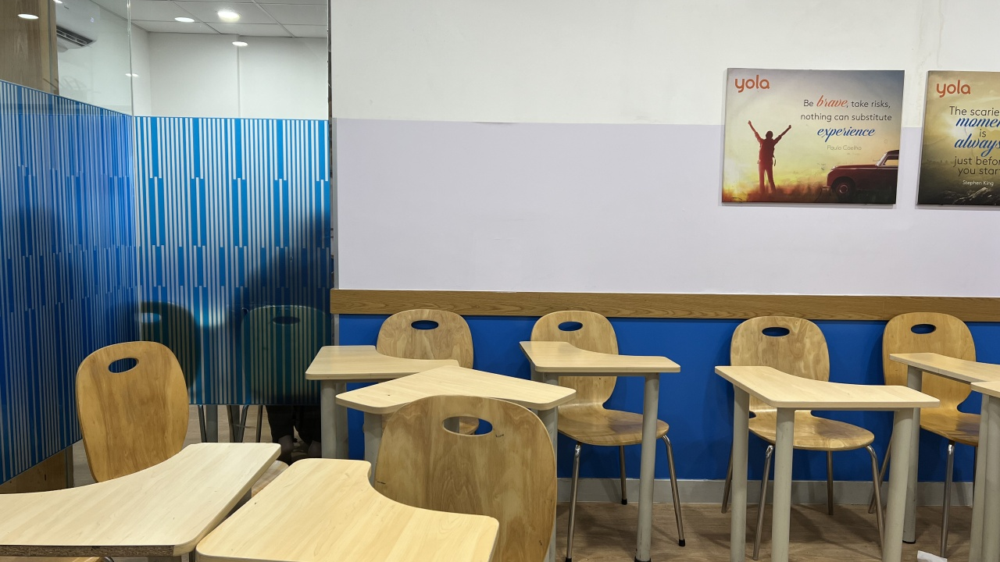

Input B


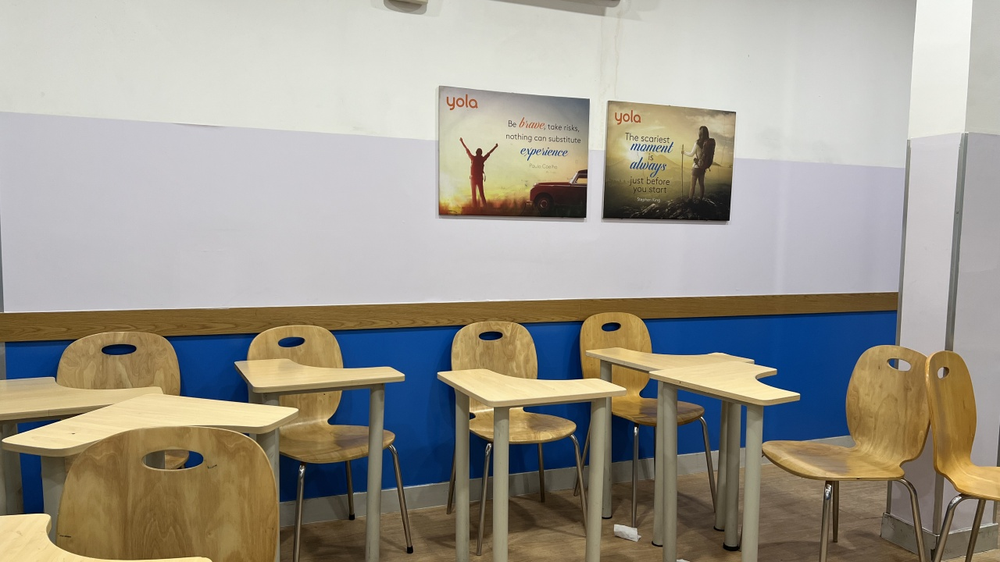

Panorama


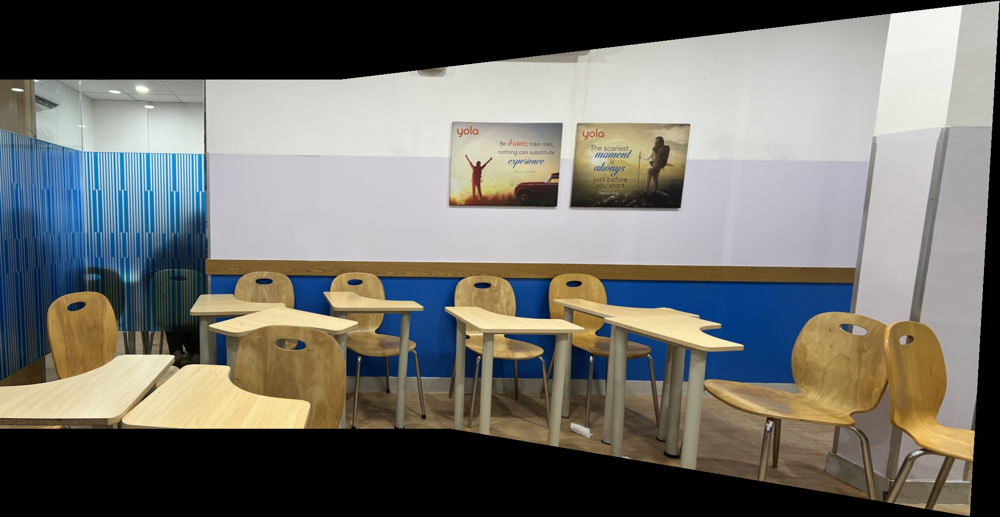


Site: site2_outdoor
Input A


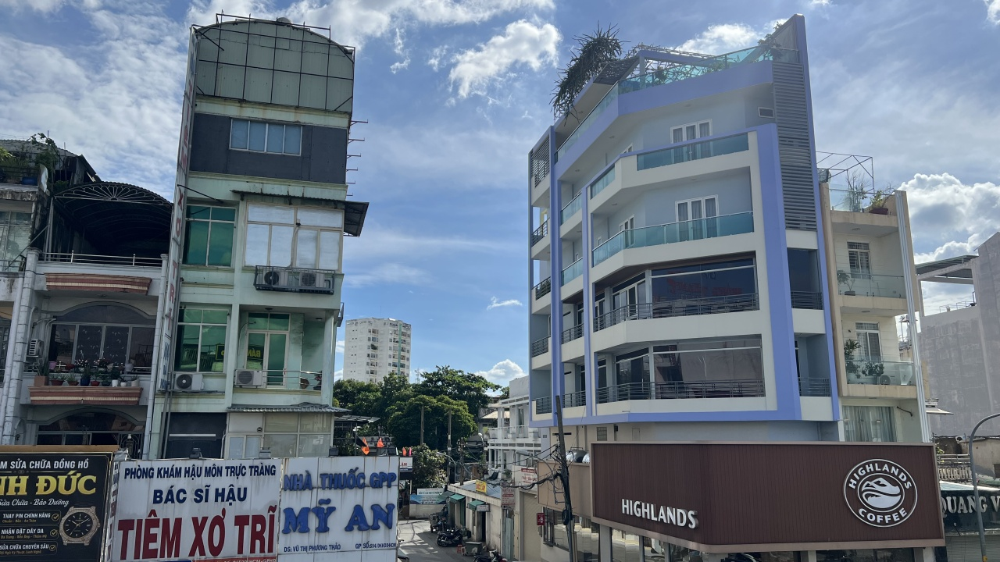

Input B


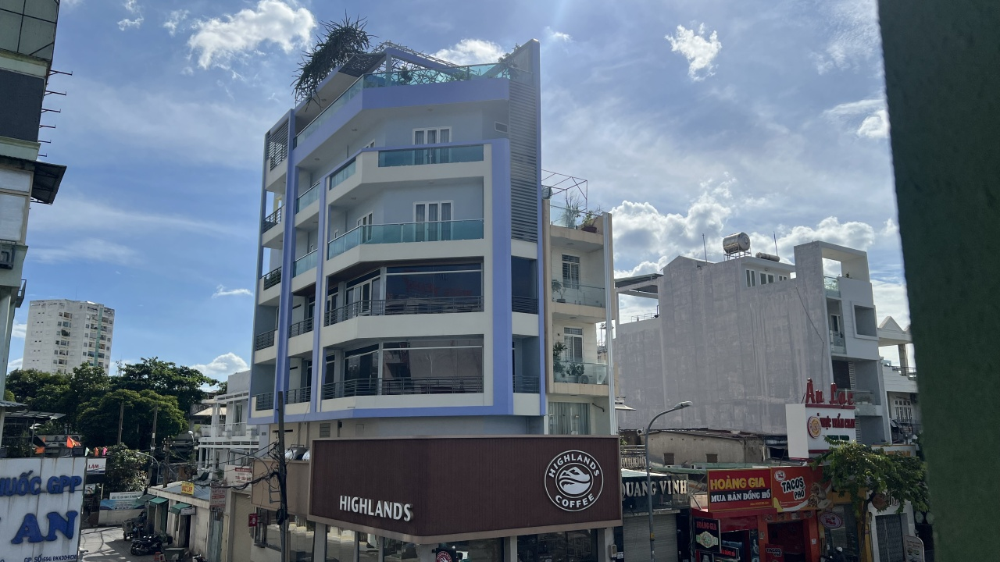

Panorama


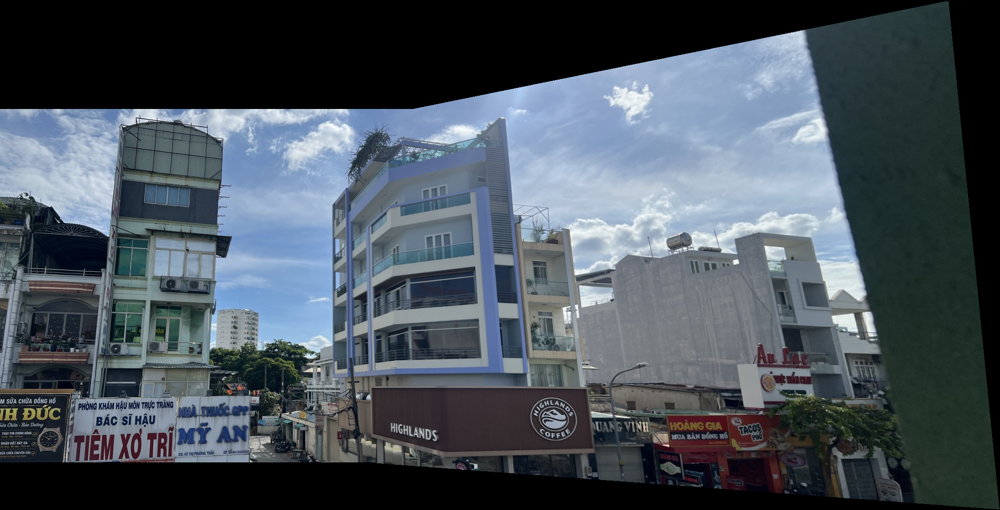


Site: site3_custom
Input A


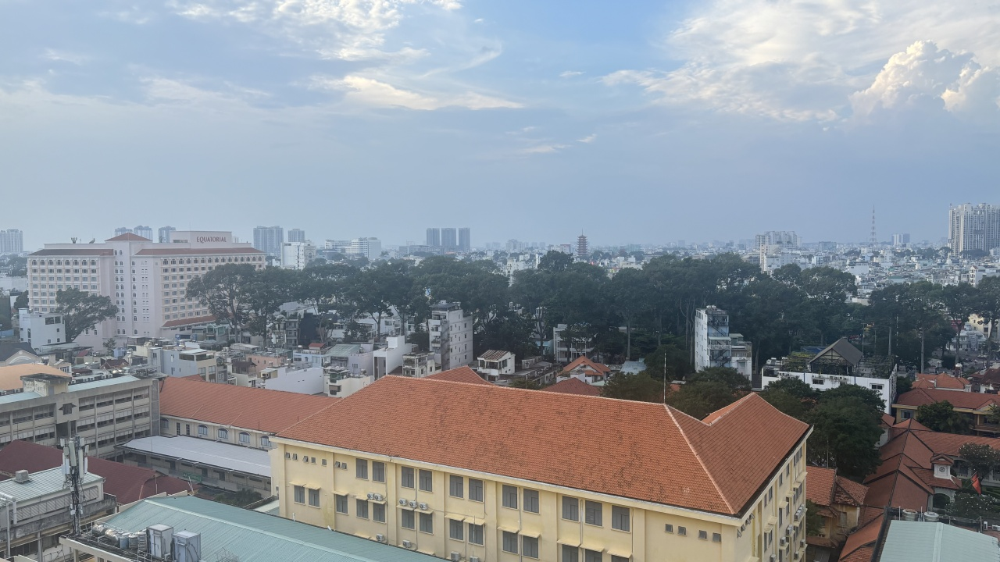

Input B


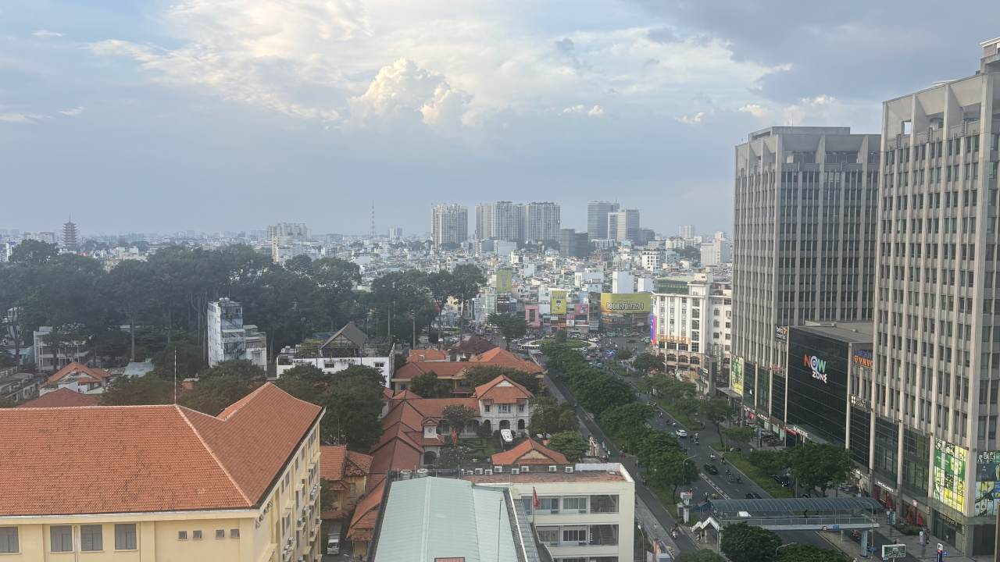

Panorama


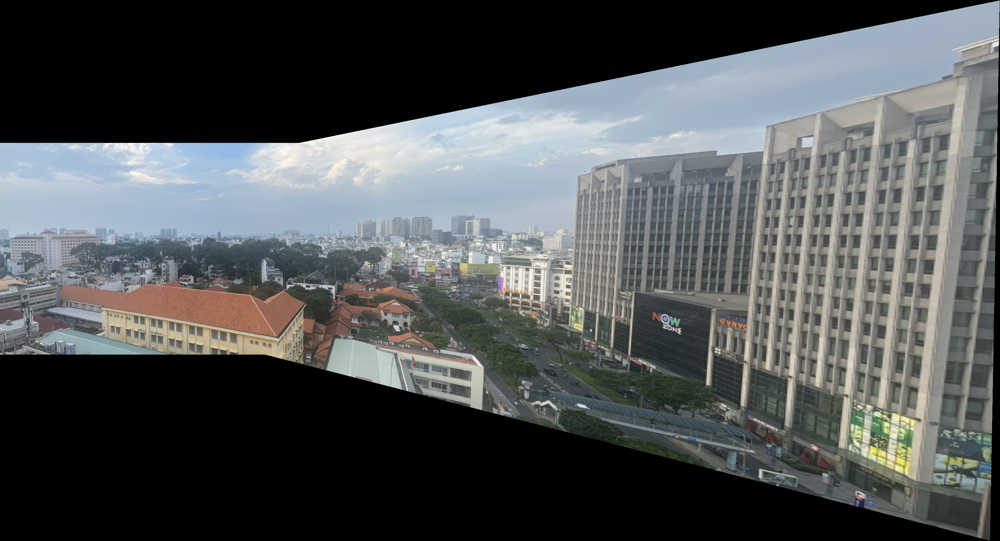


Site: challenging_pair
Input A


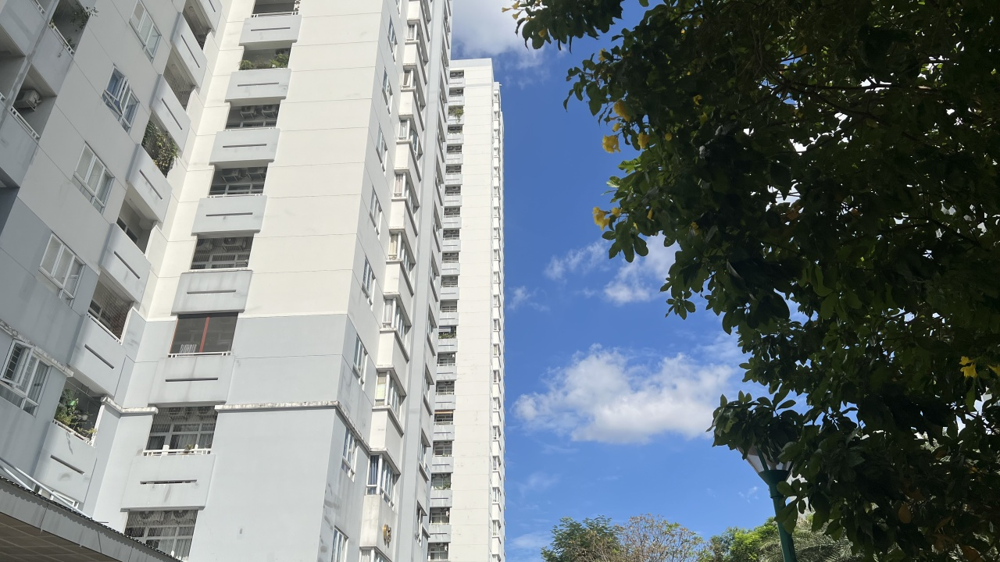

Input B


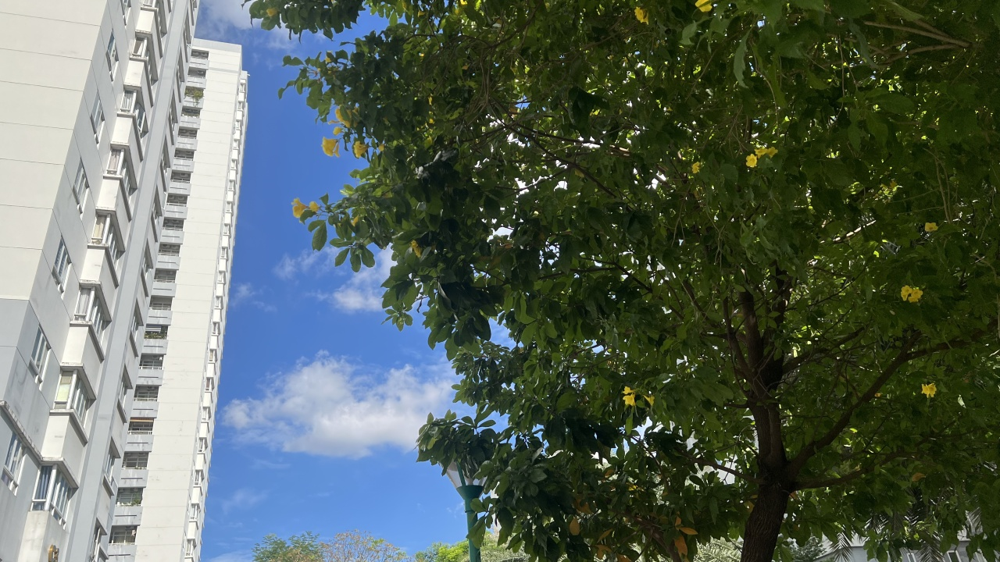

Panorama


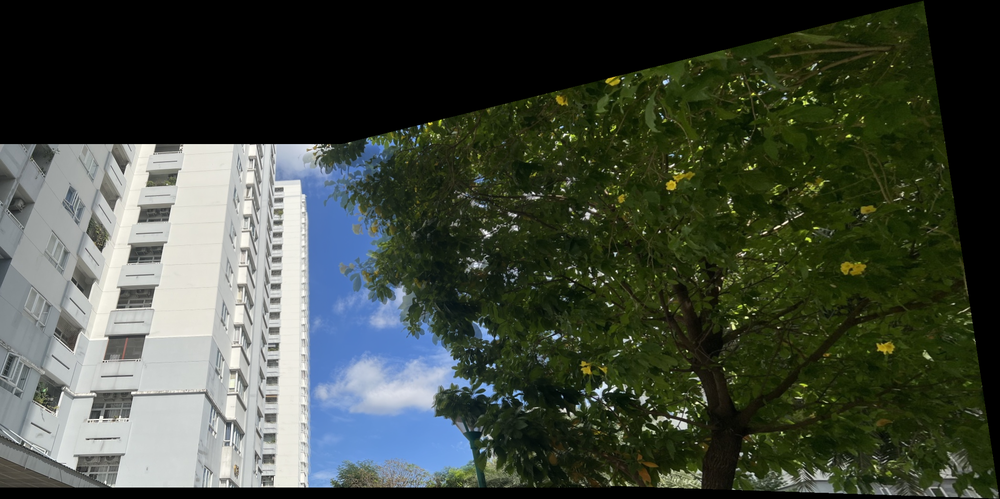

gpu,site,resolution,status,matches,inliers,inlier_ratio,inlier_rmse_px,quality_status
Tesla T4,site1_indoor,1280x720,ok,120,113,0.9417,1.0021,measured
Tesla T4,site1_indoor,1920x1080,ok,155,144,0.9290,1.2615,measured
Tesla T4,site1_indoor,3840x2160,ok,231,173,0.7489,1.4730,measured
Tesla T4,site2_outdoor,1280x720,ok,442,419,0.9480,1.1693,measured
Tesla T4,site2_outdoor,1920x1080,ok,663,603,0.9095,1.3190,measured
Tesla T4,site2_outdoor,3840x2160,ok,536,395,0.7369,1.4792,measured
Tesla T4,site3_custom,1280x720,ok,308,295,0.9578,0.8335,measured
Tesla T4,site3_custom,1920x1080,ok,322,302,0.9379,1.0018,measured
Tesla T4,site3_custom,3840x2160,ok,275,237,0.8618,1.4874,measured
Tesla T4,challenging_pair,1280x720,ok,151,91,0.6026,1.7178,measured


In [41]:
print("GPU:", metadata["gpu"] or "Unavailable — CPU execution")

for job, row in zip(jobs, results):
    if job["resolution"] != "1280x720":
        continue

    print(f"\nSite: {job['site']}")
    print("Input A")
    display(Image(filename=str(ROOT / job["left"]), width=600))

    print("Input B")
    display(Image(filename=str(ROOT / job["right"]), width=600))

    if row["status"] == "ok":
        print("Panorama")
        display(Image(
            filename=str(ROOT / row["panorama"]),
            width=1000,
        ))
    else:
        print("Pipeline failed:", row["error"])

show_table(results, [
    "gpu",
    "site",
    "resolution",
    "status",
    "matches",
    "inliers",
    "inlier_ratio",
    "inlier_rmse_px",
    "quality_status",
])

In [42]:
panorama_analysis_rows = []

for row in results:
    if row["status"] != "ok":
        continue

    panorama_analysis_rows.append({
        "site": row["site"],
        "resolution": row["resolution"],
        "matches": row["matches"],
        "inliers": row["inliers"],
        "inlier_percentage": (
            100.0 * row["inliers"] / row["matches"]
            if row["matches"] else None
        ),
        "inlier_rmse_px": row.get("inlier_rmse_px"),
    })

show_table(panorama_analysis_rows, [
    "site",
    "resolution",
    "matches",
    "inliers",
    "inlier_percentage",
    "inlier_rmse_px",
])

site,resolution,matches,inliers,inlier_percentage,inlier_rmse_px
site1_indoor,1280x720,120,113,94.1667,1.0021
site1_indoor,1920x1080,155,144,92.9032,1.2615
site1_indoor,3840x2160,231,173,74.8918,1.4730
site2_outdoor,1280x720,442,419,94.7964,1.1693
site2_outdoor,1920x1080,663,603,90.9502,1.3190
site2_outdoor,3840x2160,536,395,73.6940,1.4792
site3_custom,1280x720,308,295,95.7792,0.8335
site3_custom,1920x1080,322,302,93.7888,1.0018
site3_custom,3840x2160,275,237,86.1818,1.4874
challenging_pair,1280x720,151,91,60.2649,1.7178



site1_indoor — inputs 1920x1080
Panorama dimensions 3086 × 1596
/content/panorama_project_dev/outputs/panoramas/site1_indoor/medium_1920x1080/20261112T101210Z_349f3668/indoor_v0.png


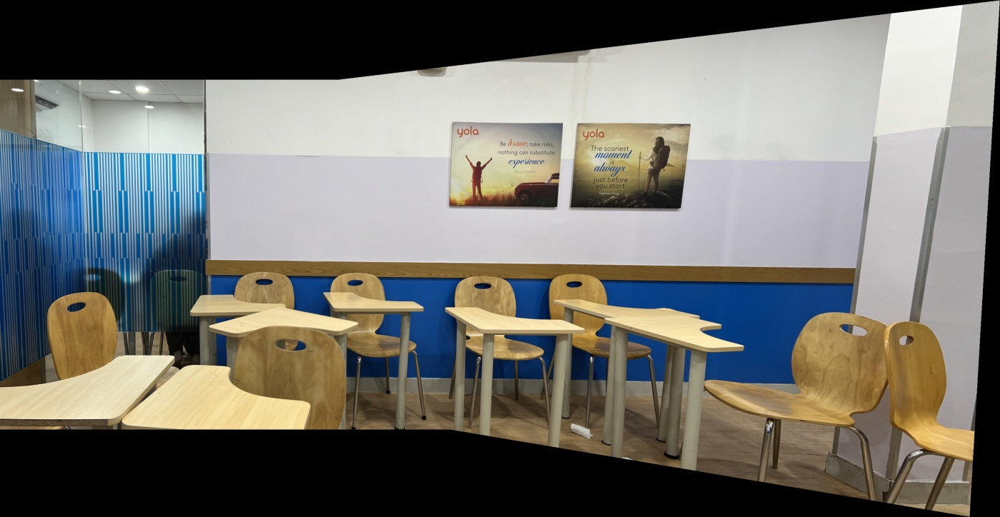


site1_indoor — inputs 3840x2160
Panorama dimensions 6133 × 3172
/content/panorama_project_dev/outputs/panoramas/site1_indoor/large_3840x2160/20261112T101210Z_349f3668/indoor_v0.png


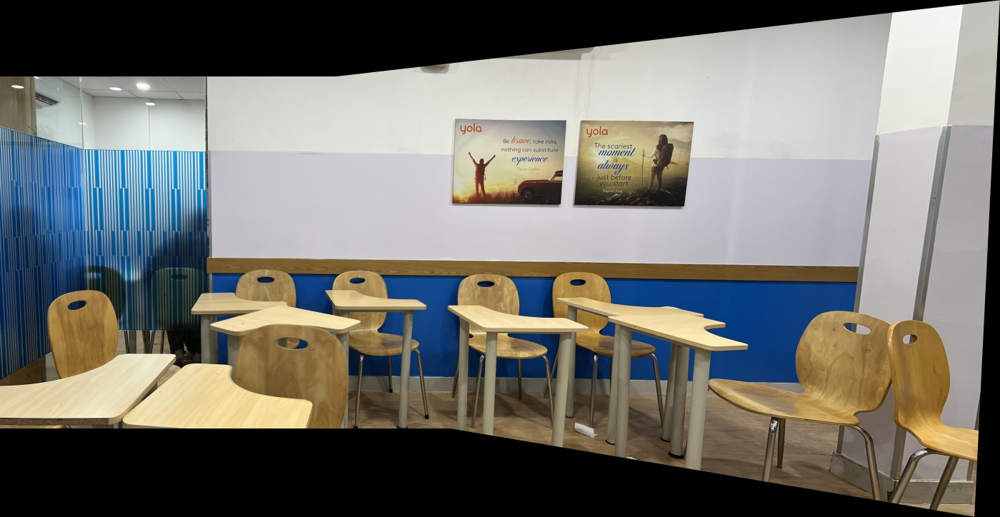


site2_outdoor — inputs 1920x1080
Panorama dimensions 3048 × 1553
/content/panorama_project_dev/outputs/panoramas/site2_outdoor/medium_1920x1080/20261112T101210Z_349f3668/outdoor_v0.png


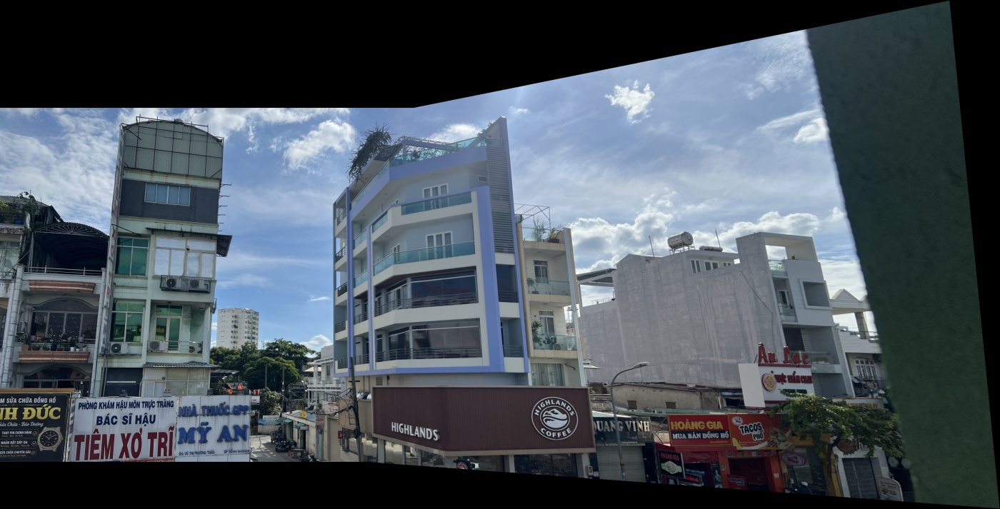


site2_outdoor — inputs 3840x2160
Panorama dimensions 6070 × 3077
/content/panorama_project_dev/outputs/panoramas/site2_outdoor/large_3840x2160/20261112T101210Z_349f3668/outdoor_v0.png


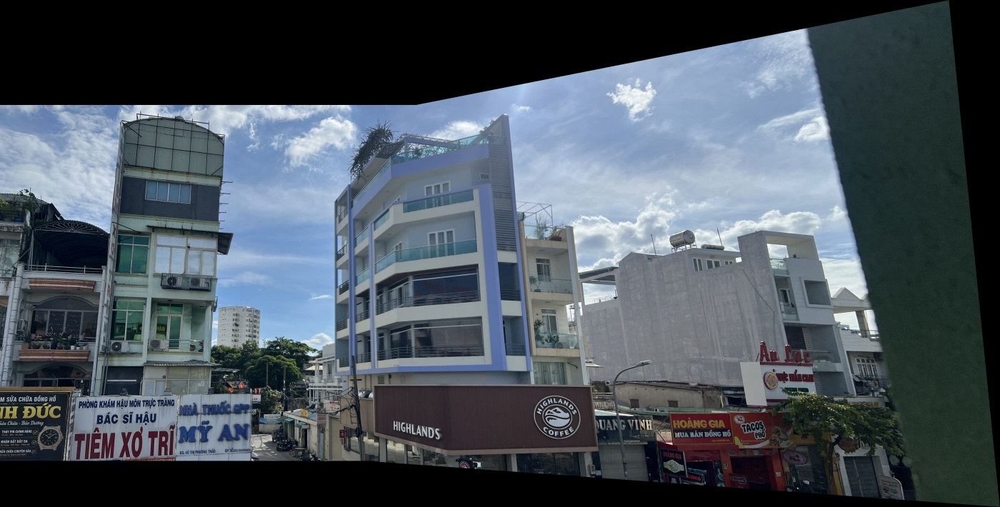


site3_custom — inputs 1920x1080
Panorama dimensions 5102 × 2761
/content/panorama_project_dev/outputs/panoramas/site3_custom/medium_1920x1080/20261112T101210Z_349f3668/skyline_v0.png


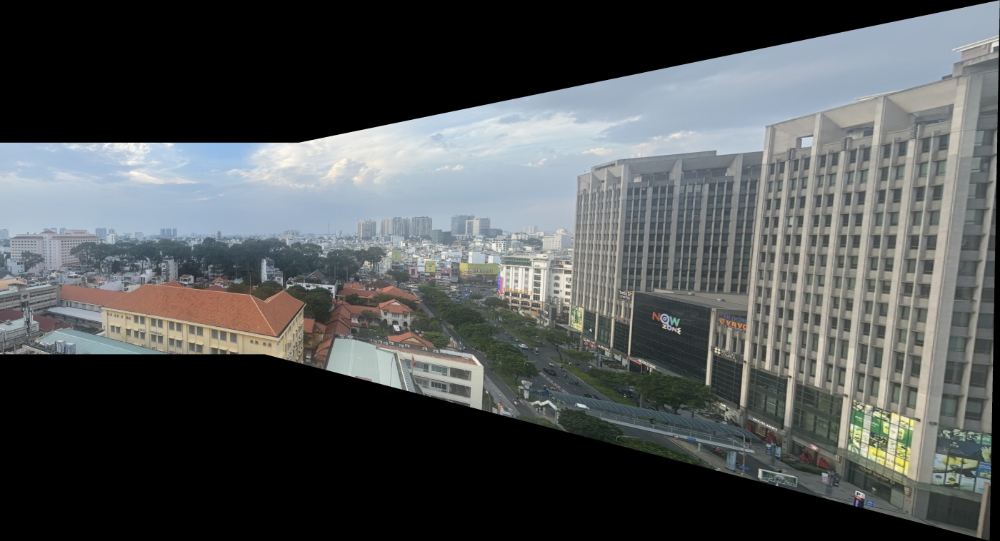


site3_custom — inputs 3840x2160
Panorama dimensions 10253 × 5550
/content/panorama_project_dev/outputs/panoramas/site3_custom/large_3840x2160/20261112T101210Z_349f3668/skyline_v0.png


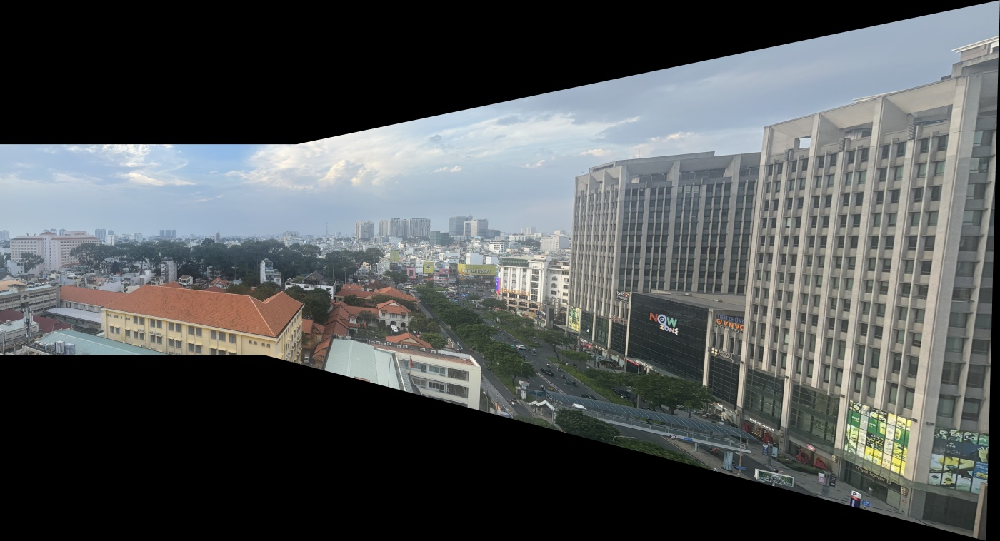


challenging_pair — inputs 1920x1080
Panorama dimensions 3105 × 1539
/content/panorama_project_dev/outputs/panoramas/challenging_pair/medium_1920x1080/20261112T101210Z_349f3668/flats_v0.png


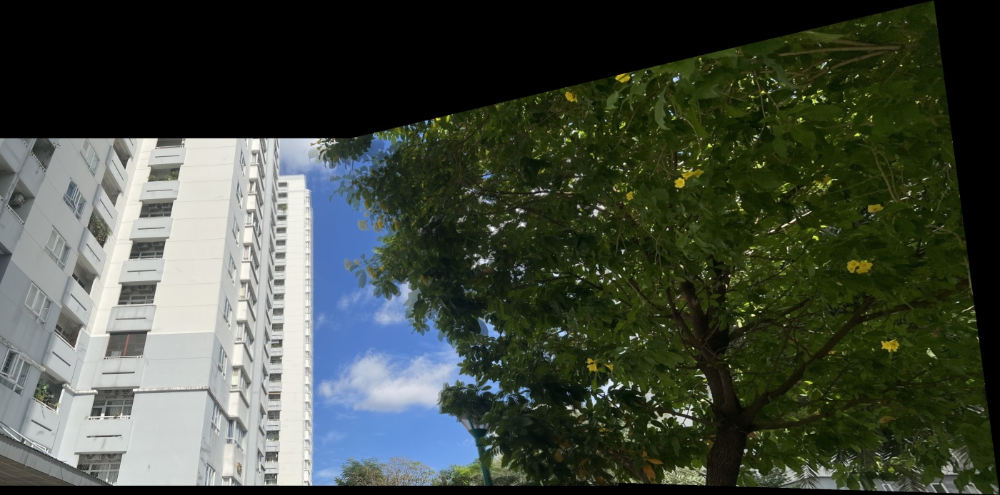


challenging_pair — inputs 3840x2160
Panorama dimensions 6377 × 3599
/content/panorama_project_dev/outputs/panoramas/challenging_pair/large_3840x2160/20261112T101210Z_349f3668/flats_v0.png


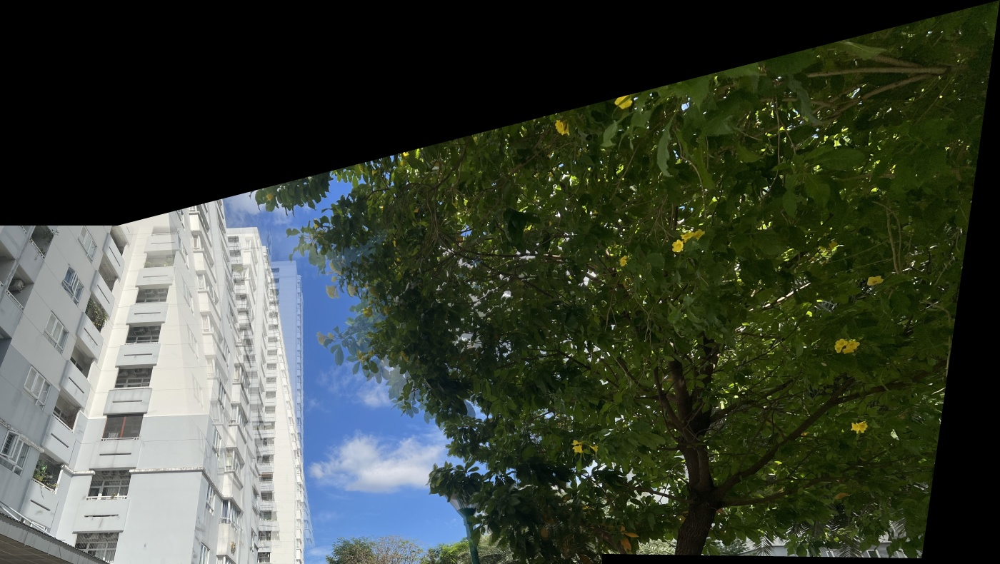

In [43]:
for row in results:
    if (
        row["status"] != "ok"
        or row["resolution"] not in {"1920x1080", "3840x2160"}
    ):
        continue

    panorama_path = ROOT / row["panorama"]

    panorama = cv2.imdecode(
        np.frombuffer(panorama_path.read_bytes(), dtype=np.uint8),
        cv2.IMREAD_COLOR,
    )

    if panorama is None:
        raise RuntimeError(f"Cannot decode {panorama_path}")

    height, width = panorama.shape[:2]
    preview_width = min(width, 1400)
    preview_height = max(1, round(height * preview_width / width))

    preview = cv2.resize(
        panorama,
        (preview_width, preview_height),
        interpolation=cv2.INTER_AREA,
    )

    success, encoded = cv2.imencode(
        ".jpg",
        preview,
        [cv2.IMWRITE_JPEG_QUALITY, 95],
    )

    if not success:
        raise RuntimeError("Cannot encode panorama preview.")

    print(f"\n{row['site']} — inputs {row['resolution']}")
    print(f"Panorama dimensions {width} × {height}")
    print(panorama_path)

    display(Image(data=encoded.tobytes()))

### 5.2 Real-image panorama analysis

We examine geometric continuity, local ghosting, brightness transitions,
and the shape of the output canvas. The displayed overviews support
assessment of the overall composition. Fine alignment defects require
closer inspection of the full-resolution images.

#### Indoor scene

The indoor panorama forms a coherent view of the classroom. The wall
posters, horizontal wooden trim, and blue lower wall remain broadly
continuous across the combined image. The output retains the desks,
chairs, and partition visible across the scene.

At 1080p, the estimated homography has 144 inliers from 155 accepted
matches, giving an inlier ratio of approximately 92.9%. The inlier
reprojection RMSE is approximately 1.262 pixels.

The wall and posters provide clear reference structures for judging
alignment. Local softness remains visible around some furniture edges.
The scene contains objects at different depths, so a single homography
may align the wall more closely than nearby desks and chairs.

The 4K overview preserves a similar overall arrangement. Its inlier
ratio decreases to approximately 74.9%, while the inlier RMSE rises to
approximately 1.473 pixels. Increasing the input resolution therefore
does not produce a corresponding improvement in these fitting metrics.

#### Outdoor street scene

The outdoor panorama combines the street-facing buildings into a
recognizable continuous scene. The central purple-and-white building
and its storefront retain coherent outlines in the overview, providing
evidence of useful alignment across the shared content.

At 1080p, the model has 603 inliers from 663 accepted matches,
approximately 91.0%, with an inlier RMSE of approximately 1.319 pixels.
This scene supplies many supporting correspondences.

Brightness varies across the sky, and the transition between source
views remains perceptible. Feather blending smooths the combination,
while the output still contains visible tonal variation.

The right side of the panorama is tilted relative to the reference
image, producing an inclined upper boundary and uncovered canvas.
The 4K overview retains similar scene geometry, with an inlier ratio
of approximately 73.7% and an inlier RMSE of approximately 1.479 pixels.

#### Skyline scene

The skyline panorama preserves the distant city, foreground roofs,
road, and large building on the right. The overview shows broad
continuity of these structures across the combined view.

At 1080p, the model has 302 inliers from 322 accepted matches,
approximately 93.8%, with an inlier RMSE of approximately 1.002 pixels.
These measurements indicate strong agreement among the accepted
correspondences.

The output also exhibits substantial projective stretching toward the
right-hand building. Its apparent size and orientation vary across the
panorama, and the rectangular canvas contains large uncovered regions
above and below the image footprint.

The 4K overview retains this overall geometry. Its inlier ratio is
approximately 86.2%, with an inlier RMSE of approximately 1.487 pixels.
The supporting-match statistics remain strong, although the visual
presentation still includes pronounced perspective distortion.

#### Challenging scene

The challenging panorama combines a nearby tree canopy with an
apartment building behind it. Repeated leaves and branches create
ambiguous local appearances, while the foreground and background occupy
different depths.

At 1080p, the model has 61 inliers from 156 accepted matches,
approximately 39.1%, with an inlier RMSE of approximately 1.368 pixels.
The resulting panorama remains recognizable, although the overlap
contains softened or doubled detail around the building and foliage.

The 4K result shows more conspicuous ghosting along the apartment
building. A displaced, partially transparent outline is visible beside
the facade against the sky.

At 4K, only 17 of 86 accepted matches support the estimated model,
approximately 19.8%. The inlier RMSE is approximately 1.096 pixels.
The visible building misalignment remains substantial despite this
small residual on the selected inliers.

These observations are consistent with the limitations of a single
global homography in a scene containing depth variation and ambiguous
foliage. Identifying the contribution of each cause would require
inspection of the supporting correspondences.

#### Effect of resolution

| Pair | Inlier ratio at 720p | Inlier ratio at 1080p | Inlier ratio at 4K |
|---|---:|---:|---:|
| Indoor | 94.2% | 92.9% | 74.9% |
| Outdoor | 94.8% | 91.0% | 73.7% |
| Skyline | 95.8% | 93.8% | 86.2% |
| Challenging pair | 60.3% | 39.1% | 19.8% |

The three standard scenes retain broadly similar overall compositions
between the inspected 1080p and 4K outputs. The challenging pair shows
a larger deterioration in geometric support and visible alignment.

Several implementation choices affect this comparison. The keypoint
limit remains fixed as resolution increases, and the RANSAC threshold
remains fixed in pixels. Consequently, feature density and the
threshold's size relative to scene structures change with resolution.

The measurements show that additional input pixels alone do not ensure
better matching or a more accurate panorama.

#### Canvas coverage and blending

All inspected panoramas contain black areas around their transformed
image footprints. The implementation stores the union of the source
footprints in a rectangular canvas and fills uncovered locations with
black.

Cropping could remove some of these borders, at the cost of discarding
part of the available scene. The present outputs preserve the full
computed canvas.

Feather blending gives gradual transitions through overlapping regions.
Where corresponding structures are displaced, averaging their colors
can produce softened or doubled edges. The challenging building
provides the clearest example in these outputs.

#### Assessment of the sequential baseline

The indoor, outdoor, and skyline results provide usable baseline
panoramas with broadly coherent scene structure. Their remaining
defects include local softness, tonal transitions, perspective
stretching, and uncovered canvas.

The challenging pair exposes a stronger limitation through reduced
geometric support and visible building ghosting, especially at 4K.
Its evaluation therefore records both successful pipeline execution
and the remaining visual alignment defects.

## Per-stage timing table

In [44]:
show_table(results, [
    "gpu",
    "site",
    "resolution",
    "status",
    *[f"stage_{stage}_mean_ms" for stage in range(1, 7)],
    "end_to_end_mean_ms",
    "end_to_end_min_ms",
])

successful_results = [
    row for row in results
    if row["status"] == "ok"
]

failed_results = [
    row for row in results
    if row["status"] != "ok"
]

if failed_results:
    print("Failed cases — excluded from timing charts:")
    show_table(failed_results, [
        "site", "resolution", "error", "log",
    ])

gpu,site,resolution,status,stage_1_mean_ms,stage_2_mean_ms,stage_3_mean_ms,stage_4_mean_ms,stage_5_mean_ms,stage_6_mean_ms,end_to_end_mean_ms,end_to_end_min_ms
Tesla T4,site1_indoor,1280x720,ok,16.0740,80.9890,2.0000,1.3660,4.7690,117.9010,223.1020,219.3020
Tesla T4,site1_indoor,1920x1080,ok,39.1950,188.6800,3.0450,3.0150,5.5790,264.9050,504.4230,496.8650
Tesla T4,site1_indoor,3840x2160,ok,184.7200,893.0700,6.4310,12.5460,6.1800,1141.5940,2244.5460,2037.2160
Tesla T4,site2_outdoor,1280x720,ok,24.6950,110.7630,9.4240,32.0420,14.5730,140.4850,331.9880,252.9160
Tesla T4,site2_outdoor,1920x1080,ok,37.3000,195.8350,11.5000,48.0540,16.7790,261.8870,571.3600,562.4640
Tesla T4,site2_outdoor,3840x2160,ok,161.8420,912.8150,14.1580,66.5360,14.0340,1115.0490,2284.4390,2090.7080
Tesla T4,site3_custom,1280x720,ok,30.6500,104.4940,13.3650,70.6360,12.5180,315.2750,546.9430,473.0060
Tesla T4,site3_custom,1920x1080,ok,38.7440,196.4150,13.0870,55.1000,8.9670,566.9410,879.2590,874.8100
Tesla T4,site3_custom,3840x2160,ok,183.6730,905.0770,14.5790,63.0890,8.4360,2347.4140,3522.2740,3322.3270
Tesla T4,challenging_pair,1280x720,ok,15.6820,81.5950,8.2410,25.3350,4.4430,117.8720,253.1700,247.3140


## Timing charts

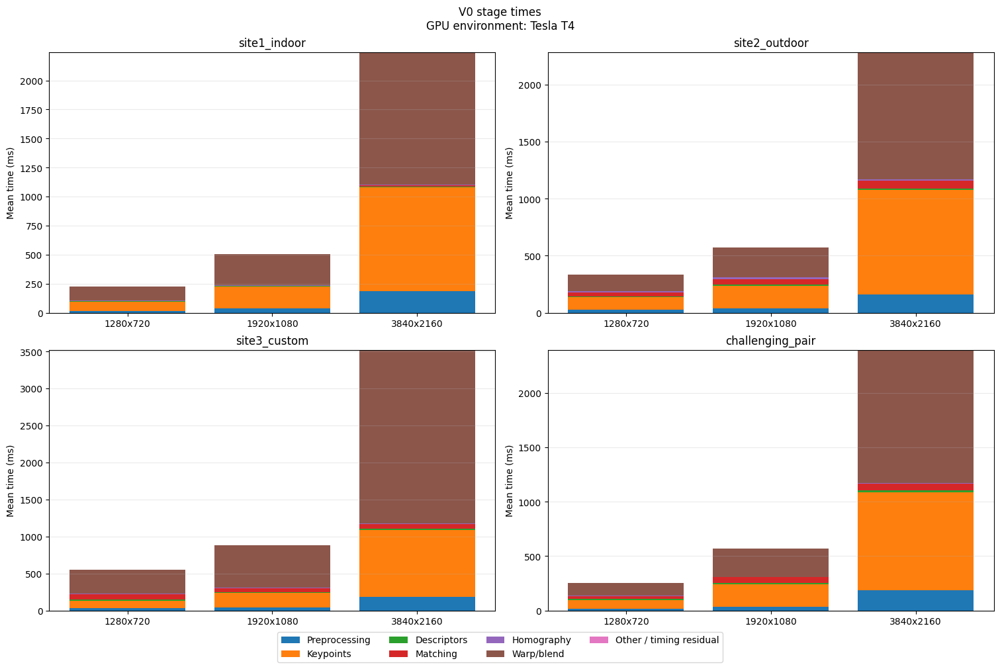

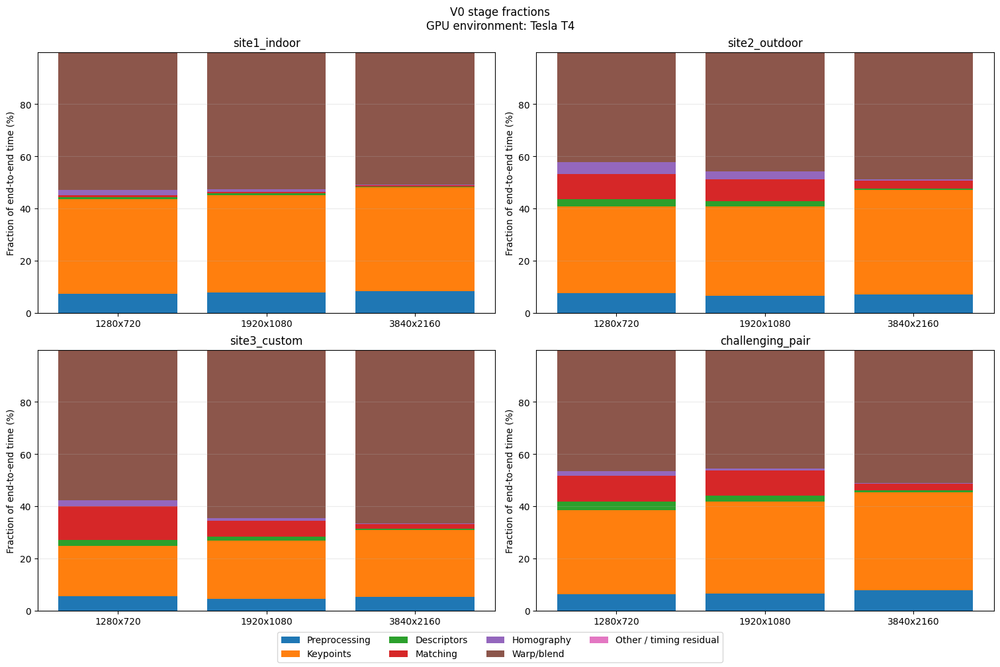

In [45]:
stage_labels = [
    "Preprocessing",
    "Keypoints",
    "Descriptors",
    "Matching",
    "Homography",
    "Warp/blend",
]

resolution_order = [
    "1280x720",
    "1920x1080",
    "3840x2160",
]

sites = [site for site, _ in benchmark_runner.CASES]
colors = plt.get_cmap("tab10").colors

def plot_stage_times(relative=False):
    figure, axes = plt.subplots(
        2, 2,
        figsize=(15, 10),
        constrained_layout=True,
    )

    for axis, site in zip(axes.ravel(), sites):
        rows = sorted(
            [
                row for row in successful_results
                if row["site"] == site
            ],
            key=lambda row: resolution_order.index(row["resolution"]),
        )

        if not rows:
            axis.set_title(f"{site}: no successful results")
            continue

        totals = np.array([
            row["end_to_end_mean_ms"] for row in rows
        ])

        values = np.array([
            [
                row[f"stage_{stage}_mean_ms"]
                for row in rows
            ]
            for stage in range(1, 7)
        ])

        # Small differences also include printed timing precision.
        residual = totals - values.sum(axis=0)

        if np.any(residual < -0.01):
            raise RuntimeError(
                "Stage sum exceeds total beyond rounding tolerance."
            )

        values = np.vstack((values, np.maximum(residual, 0.0)))
        labels = stage_labels + ["Other / timing residual"]

        if relative:
            values = values / totals[None, :] * 100.0

        positions = np.arange(len(rows))
        bottom = np.zeros(len(rows))

        for index, label in enumerate(labels):
            axis.bar(
                positions,
                values[index],
                bottom=bottom,
                label=label,
                color=colors[index],
            )
            bottom += values[index]

        axis.set_xticks(
            positions,
            [row["resolution"] for row in rows],
        )
        axis.set_title(site)
        axis.set_ylabel(
            "Fraction of end-to-end time (%)"
            if relative
            else "Mean time (ms)"
        )
        axis.grid(axis="y", alpha=0.25)

    handles, labels = axes.ravel()[0].get_legend_handles_labels()

    figure.legend(
        handles,
        labels,
        loc="outside lower center",
        ncol=4,
    )

    gpu_name = (
        metadata["gpu"]["name"]
        if metadata["gpu"]
        else "Unavailable — local CPU execution"
    )

    figure.suptitle(
        f"V0 stage {'fractions' if relative else 'times'}"
        f"\nGPU environment: {gpu_name}"
    )

    filename = (
        "stage_fractions.png" if relative else "stage_times.png"
    )

    figure.savefig(
        batch_directory / filename,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()


plot_stage_times(relative=False)
plot_stage_times(relative=True)

## Calculate dominant stages

In [46]:
hot_stage_rows = []

for row in successful_results:
    ordered = sorted(
        range(1, 7),
        key=lambda stage: row[f"stage_{stage}_mean_ms"],
        reverse=True,
    )

    first, second = ordered[:2]
    total = row["end_to_end_mean_ms"]

    hot_stage_rows.append({
        "site": row["site"],
        "resolution": row["resolution"],
        "dominant_stage": stage_labels[first - 1],
        "dominant_fraction_percent": (
            100.0 * row[f"stage_{first}_mean_ms"] / total
        ),
        "second_stage": stage_labels[second - 1],
        "second_fraction_percent": (
            100.0 * row[f"stage_{second}_mean_ms"] / total
        ),
    })

show_table(hot_stage_rows, [
    "site",
    "resolution",
    "dominant_stage",
    "dominant_fraction_percent",
    "second_stage",
    "second_fraction_percent",
])

site,resolution,dominant_stage,dominant_fraction_percent,second_stage,second_fraction_percent
site1_indoor,1280x720,Warp/blend,52.8462,Keypoints,36.3013
site1_indoor,1920x1080,Warp/blend,52.5164,Keypoints,37.4051
site1_indoor,3840x2160,Warp/blend,50.8608,Keypoints,39.7884
site2_outdoor,1280x720,Warp/blend,42.3163,Keypoints,33.3636
site2_outdoor,1920x1080,Warp/blend,45.8357,Keypoints,34.2752
site2_outdoor,3840x2160,Warp/blend,48.8106,Keypoints,39.9580
site3_custom,1280x720,Warp/blend,57.6431,Keypoints,19.1051
site3_custom,1920x1080,Warp/blend,64.4794,Keypoints,22.3387
site3_custom,3840x2160,Warp/blend,66.6448,Keypoints,25.6958
challenging_pair,1280x720,Warp/blend,46.5584,Keypoints,32.2293


### 5.3 Hot-stage analysis

Warping and blending is the largest measured stage in every tested
case. Keypoint detection is consistently the second-largest stage.
These results make Stages 6 and 2 the first priorities for GPU work.

For the indoor pair at 1080p, warping and blending accounts for
approximately 52.19% of end-to-end time, while keypoint detection
accounts for approximately 38.27%. Together, they occupy approximately
90.46% of the measured pipeline time.

The skyline pair places a larger fraction of its workload in Stage 6.
Its warping and blending share increases from approximately 61.14% at
720p to 66.78% at 4K. The skyline panorama has a large transformed
canvas, so Stage 6 processes substantially more output pixels than
the dimensions of either input image alone would suggest.

The relative cost of matching also depends on retained keypoint counts.
The detector caps each image at 2,000 keypoints, so descriptor and
matching workloads do not necessarily increase proportionally with
input pixel count.

The measurements support the following implementation order:

1. Parallelize the output-pixel work in warping and blending.
2. Parallelize the image-wide gradient, response, and suppression
   calculations in keypoint detection.
3. Implement the remaining stages to complete V1.
4. Profile V1 before choosing the first optimization.

The priority order concerns development effort. The complete V1 plan
still covers all six stages.

## Amdahl estimate

In [47]:
amdahl_rows = []

for row in successful_results:
    total_time = row["end_to_end_mean_ms"]

    accelerated_time = (
        row["stage_2_mean_ms"]
        + row["stage_6_mean_ms"]
    )

    remaining_time = total_time - accelerated_time

    if remaining_time <= 0:
        raise ValueError(
            "Amdahl calculation requires positive remaining time."
        )

    fraction = accelerated_time / total_time

    amdahl_rows.append({
        "site": row["site"],
        "resolution": row["resolution"],
        "accelerated_stages": "2 and 6",
        "p": fraction,
        "accelerated_percentage": 100.0 * fraction,
        "remaining_time_ms": remaining_time,
        "ideal_speedup_limit": 1.0 / (1.0 - fraction),
    })

show_table(amdahl_rows, [
    "site",
    "resolution",
    "accelerated_stages",
    "p",
    "accelerated_percentage",
    "remaining_time_ms",
    "ideal_speedup_limit",
])

benchmark_runner.write_csv(
    batch_directory / "amdahl_estimates.csv",
    amdahl_rows,
)

site,resolution,accelerated_stages,p,accelerated_percentage,remaining_time_ms,ideal_speedup_limit
site1_indoor,1280x720,2 and 6,0.8915,89.1476,24.2120,9.2145
site1_indoor,1920x1080,2 and 6,0.8992,89.9216,50.8380,9.9222
site1_indoor,3840x2160,2 and 6,0.9065,90.6492,209.8820,10.6943
site2_outdoor,1280x720,2 and 6,0.7568,75.6798,80.7400,4.1118
site2_outdoor,1920x1080,2 and 6,0.8011,80.1110,113.6380,5.0279
site2_outdoor,3840x2160,2 and 6,0.8877,88.7686,256.5750,8.9036
site3_custom,1280x720,2 and 6,0.7675,76.7482,127.1740,4.3007
site3_custom,1920x1080,2 and 6,0.8682,86.8181,115.9030,7.5862
site3_custom,3840x2160,2 and 6,0.9234,92.3407,269.7830,13.0560
challenging_pair,1280x720,2 and 6,0.7879,78.7878,53.7030,4.7143


### 5.4 Amdahl estimate and implications

We estimate the ideal benefit of accelerating the two dominant stages,
keypoint detection and warping/blending.

For their measured fraction $p$ of V0 end-to-end time, Amdahl's law
gives:

$$
S_{\max} = \frac{1}{1-p}.
$$

For the indoor pair at 1080p, the measured fraction is approximately
$p = 0.9046$, giving an ideal maximum speedup of approximately 10.48×.

For the skyline pair at 4K, the measured fraction is approximately
$p = 0.9235$, giving an ideal maximum speedup of approximately 13.08×.

These estimates assume that the entire measured duration of the selected
stages can be reduced arbitrarily while the remaining work stays fixed.

The full V1 plan covers all six stages. Its achievable speedup must
also account for the CPU work retained in GPU wrappers, host–device
transfers, allocations, kernel launches, and synchronization.

We therefore use the dominant-stage scenario as the concrete planning
estimate and will measure the complete GPU pipeline when V1 is available.

In [48]:
section5_summary = {
    "benchmark_directory": batch_directory.relative_to(ROOT).as_posix(),
    "synthetic_directory": (
        SYNTHETIC_DIRECTORY.relative_to(ROOT).as_posix()
    ),
    "environment": metadata["environment"],
    "gpu": metadata["gpu"],
    "timed_runs_per_case": RUNS,
    "successful_real_cases": len(successful_results),
    "failed_real_cases": len(failed_results),
    "synthetic_cases_measured": sum(
        row["status"] == "measured"
        for row in synthetic_results
    ),
    "synthetic_cases_total": len(synthetic_results),
}

benchmark_runner.write_json(
    batch_directory / "section5_summary.json",
    section5_summary,
)

print(json.dumps(section5_summary, indent=2))
print("\nRetain these cell outputs in the submitted notebook.")

{
  "benchmark_directory": "outputs/benchmarks/20261112T101210Z_349f3668",
  "synthetic_directory": "outputs/validation/synthetic_eb00284e",
  "environment": "Colab GPU baseline",
  "gpu": {
    "name": "Tesla T4",
    "uuid": "GPU-169f8d10-a6fe-80cf-cda5-48e062f20e9c",
    "driver": "580.82.07"
  },
  "timed_runs_per_case": 5,
  "successful_real_cases": 12,
  "failed_real_cases": 0,
  "synthetic_cases_measured": 3,
  "synthetic_cases_total": 3
}

Retain these cell outputs in the submitted notebook.


## 6. Dataset

### 6.1 Dataset access

The dataset is available through the team's shared folder:

[Team dataset](https://drive.google.com/drive/folders/1Saplb-gGh9_TM0MExYXlqH89Je0stNu9?usp=sharing)

The shared dataset should contain both the raw photographs and the
prepared `dataset/` directory. The source setup checks the prepared
inputs before running any benchmark.

### 6.2 Sites and image pairs

| Folder | Pair prefix | Scene | Role |
|---|---|---|---|
| `site1_indoor` | `indoor` | Classroom with desks, chairs, wall posters, and a partition | Standard indoor pair |
| `site2_outdoor` | `outdoor` | Street-facing buildings and storefronts | Standard outdoor pair |
| `site3_custom` | `skyline` | City skyline, roofs, road, and a large nearby building | Third standard pair |
| `challenging_pair` | `flats` | Apartment building behind a nearby tree canopy | Challenging pair |

The challenging scene contains repeated foliage and structures at
different depths. These properties make descriptor matching and
alignment with one global homography more difficult.

### 6.3 Capture record

The following administrative and capture details require confirmation
against the team's registration and capture records.

| Pair | Registered site name/location | Capture date/device | Capture notes |
|---|---|---|---|
| Indoor | YOLA Classroom | 10/11/2026 - iPhone 13 Pro Max | Record camera motion, overlap, and lighting |
| Outdoor | Phuc Long 76 Ba Hom | 11/11/2026 - iPhone 13 Pro Max | Record camera motion, overlap, and lighting |
| Skyline | HCMUS - I Building | 7/11/2026 - iPhone 15 Plus | Record camera motion, overlap, and lighting |
| Challenging | Him Lam - Cho Lon Apartment Complex | 11/11/2026 - iPhone 13 Pro Max| Record camera motion, overlap, and repeated objects |

### 6.4 Dataset preparation

The preparation script reads PNG, JPEG, HEIC, and HEIF input files.
HEIC/HEIF decoding uses Pillow and pillow-heif, including EXIF-based
orientation correction.

For each decoded image, the script:

1. Selects a centered 16:9 crop.
2. Generates each target resolution directly from that crop.
3. Uses OpenCV area interpolation when downsampling.
4. Uses cubic interpolation when upsampling is required.
5. Saves the prepared image as JPEG with quality 95.

Generating each resolution from the original crop avoids accumulating
interpolation effects from repeated resizing.

| Folder | Prepared dimensions |
|---|---|
| `small_1280x720` | 1280 × 720 |
| `medium_1920x1080` | 1920 × 1080 |
| `large_3840x2160` | 3840 × 2160 |

Each of the four pairs has two prepared images at each resolution,
giving 24 prepared images and 12 pair/resolution cases.

The setup records input hashes and checks image dimensions. The report's
input displays provide a visual record of the prepared pairs.

## 7. GPU implementation plan

### 7.1 Scope and priorities

V1 will implement the computational work of all six stages on the GPU.
The V0 profile identifies warping/blending and keypoint detection as
the first implementation priorities.

V0 remains the reference for algorithm definitions and output checks.
The Gaussian coefficients, BRIEF pattern, thresholds, keypoint limit,
RANSAC samples, and tie-breaking rules will remain consistent.

### 7.2 Initial V1 thread mapping

| Stage | Planned mapping | Coordination and correctness requirements |
|---|---|---|
| Preprocessing | One thread per output pixel for grayscale conversion and for each Gaussian pass | Preserve clamped boundary sampling and filter accumulation order where practical |
| Harris detection | One thread per pixel for gradients, response, and local suppression | Separate candidate compaction and top-K selection; preserve response and coordinate tie-breaking |
| BRIEF | One thread per keypoint, computing its descriptor words | Preserve sample coordinates, strict intensity comparisons, and bit packing |
| Matching | One block per query descriptor; threads scan subsets of the other descriptor set | Reduce best and second-best candidates using distance and index; compute reverse nearest neighbors and apply mutual checking |
| RANSAC | One block per hypothesis; one lane fits the small system and threads score correspondences | Reduce inlier counts, select the earliest best hypothesis on ties, and refine the selected model |
| Warping/blending | One thread per output canvas pixel | Apply the inverse homography, sample valid sources, and combine their weighted colors |

For matching, the initial implementation may calculate forward and
reverse nearest neighbors in separate passes. This keeps ownership of
each output record explicit. Accepted matches will be compacted in
reference-keypoint order.

For RANSAC, hypothesis samples must reproduce V0's deterministic sample
sequence. Any host-side sample preparation and associated transfers
will be included in the documented pipeline scope.

Homography refinement will use the selected inlier set. Its reductions
and small-system solve must follow the same fitting definition as V0.

### 7.3 Planned optimization experiments

The optimization selected for each later version will follow profiling
of its immediate predecessor.

| Candidate optimization | Motivation | Expected benefit | Main risk |
|---|---|---|---|
| Shared-memory tiling for blur and local image operations | Neighboring pixels repeatedly read overlapping neighborhoods | Reduce repeated global-memory loads | Halo handling, synchronization, and shared-memory usage may offset the benefit |
| Tiled descriptor matching with population-count operations and block/warp reductions | Descriptor data is reused across many comparisons | Reduce memory traffic and improve comparison throughput | Register pressure, occupancy, and correct nearest-neighbor tie handling |
| Concurrent processing of images A and B | Preprocessing and feature extraction are independent before matching | Overlap independent work where resources permit | Additional memory demand and limited overlap when kernels already saturate the GPU |

### 7.4 Main risks and verification

Floating-point differences can affect Harris ordering, BRIEF bits,
RANSAC inlier decisions, and canvas bounds. Verification will compare
intermediate outputs where necessary, in addition to final panoramas.

Compaction and reductions must preserve deterministic ordering and
selection rules. Changes in tie handling can propagate into later
stages even when individual distance calculations are correct.

Transfer overhead and intermediate allocation costs may reduce
end-to-end speedup. We will retain intermediate data on the device
where the pipeline permits and report the resulting transfer policy.

The challenging pair also exposes a quality limitation of the chosen
model and descriptors. GPU acceleration preserves that algorithmic
behavior. A method change would require a separately documented
quality comparison.

### 7.5 Measurement and profiling plan

GPU stages will use CUDA-event timing in the relevant streams.
End-to-end timing will finish only after all required GPU work is
complete and the output is available to the host.

Each comparison will use identical inputs, one warm-up, and at least
five timed repetitions in the same Colab GPU session.

We will report per-stage time, kernel time, host–device transfer time,
end-to-end time, and speedup against V0 and the previous version.

Profiling will be executed separately from benchmark runs. V1 profiling
will motivate V2, and V2 profiling will motivate V3. The report will
retain the relevant timeline or kernel metrics and explain how they
support the selected change.

## 8. References and code provenance

### 8.1 Algorithm references

1. C. Harris and M. Stephens.
   *A Combined Corner and Edge Detector.*
   Alvey Vision Conference, 1988.
   [Publication](https://www.bmva.org/bmvc/1988/avc-88-023.html)

2. M. Calonder, V. Lepetit, C. Strecha, and P. Fua.
   *BRIEF: Binary Robust Independent Elementary Features.*
   European Conference on Computer Vision, 2010.
   [Authors' project page](https://www.epfl.ch/labs/cvlab/research/descriptors-and-keypoints/research-detect-brief/)

3. M. A. Fischler and R. C. Bolles.
   *Random Sample Consensus: A Paradigm for Model Fitting with
   Applications to Image Analysis and Automated Cartography.*
   Communications of the ACM, 1981.
   [Publication](https://doi.org/10.1145/358669.358692)

### 8.2 External libraries and tools

- `stb_image` and `stb_image_write` provide image decoding and PNG
  output. Their original source and license notices are retained.
  [stb repository](https://github.com/nothings/stb)

- OpenCV is used in dataset preparation and synthetic test generation.
  [Geometric transformation documentation](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html)

- Pillow and pillow-heif support HEIC/HEIF decoding during dataset
  preparation.
  [Pillow documentation](https://pillow.readthedocs.io/)
  [pillow-heif documentation](https://pillow-heif.readthedocs.io/)

- NumPy supports numerical evaluation in the notebook, and Matplotlib
  produces the timing charts.
  [NumPy documentation](https://numpy.org/doc/)
  [Matplotlib documentation](https://matplotlib.org/stable/)

### 8.3 AI assistance

OpenAI ChatGPT/Codex was used during development to propose
implementations, explain algorithms, review errors, design benchmark
and synthetic-validation code, and draft parts of the notebook.

The team is responsible for reviewing the submitted implementation,
understanding its behavior, verifying the results, and ensuring that
the disclosure follows the course's AI-use policy.